# Detekcija prevarnih finansijskih transakcija

Zadaci 1.1–1.4 obuhvataju odabir, analizu i pripremu podataka, a 2.1 odabir pet algoritama i raspodjelu rada. Pregled naučnih radova nalazi se u odjeljku 1.2 izvještaja.

## 1.1 Odabir i učitavanje skupa podataka

Tema je nadzirana binarna klasifikacija transakcija; cilj `is_fraud` označava legitimnu (0) ili prevarnu (1) transakciju. Izvor je [Kaggle — Credit Card Transactions Fraud Detection](https://www.kaggle.com/datasets/kartik2112/fraud-detection), sa simuliranim Sparkovim transakcijama.

Iz trening datoteke izvora formiramo dvije verzije: `fraud_balanced.csv` nasumičnim smanjivanjem većinske klase (15.012 redova, po 7.506 u svakoj klasi, seed 42) i `fraud_15k.csv` stratifikovanim uzorkovanjem (15.000 redova, 87 prevara). Obje imaju 21 ulaznu kolonu i cilj te numeričke i kategoričke varijable.

Balansirani skup omogućava pregled obrazaca obje klase, a nebalansirani čuva približan izvorni udio prevara. Zato su nam potrebne obje verzije. Ista pravila pripreme primjenjuju se na obje, uz očuvanje ulaznih CSV-ova. **Dijele 7.593 transakcije i nisu nezavisni skupovi za provjeru.**

U korijenu projekta nalaze se dvije izvedene CSV datoteke. Funkcija ispod dokumentuje kako se obje formiraju iz Kaggle trening datoteke ako je ona dostupna lokalno.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
os.environ.setdefault('MPLCONFIGDIR', '/tmp/mu-matplotlib')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Važi i kada se EDA dio pokrene zasebno.
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', None)

ROOT = Path.cwd()
if not (ROOT / 'fraud_balanced.csv').exists():
    raise FileNotFoundError('U radni direktorij učitati fraud_balanced.csv i fraud_15k.csv.')
# Sve tekstualne kolone učitavamo kao string; numeričke zadržavaju svoje tipove.
text_columns = [
    'trans_date_trans_time', 'cc_num', 'merchant', 'category',
    'first', 'last', 'gender', 'street', 'city', 'state', 'zip',
    'job', 'dob', 'trans_num'
]
read_types = {c: 'string' for c in text_columns}
sources = {name: pd.read_csv(ROOT / name, dtype=read_types)
           for name in ['fraud_balanced.csv', 'fraud_15k.csv']}
raw = sources['fraud_balanced.csv']
eda = raw.copy(deep=True)
original_columns = list(raw.columns)
continuous = ['amt', 'lat', 'long', 'city_pop', 'unix_time', 'merch_lat', 'merch_long']
categorical = ['cc_num', 'merchant', 'category', 'first', 'last', 'gender',
               'street', 'city', 'state', 'zip', 'job', 'trans_num']
semantic = {c: 'kategorički' for c in categorical}
semantic.update({c: 'numerički' for c in continuous})
semantic.update({'cc_num': 'identifikator kartice', 'trans_num': 'identifikator transakcije',
                 'zip': 'kategorički (poštanski broj)', 'unix_time': 'numerički (vrijeme)',
                 'trans_date_trans_time': 'datum/vrijeme', 'dob': 'datum',
                 'is_fraud': 'binarna ciljna klasa'})
sns.set_theme(style='whitegrid', palette=['#168B90', '#C46535'], font_scale=1.1)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 180, 'axes.titleweight': 'bold'})
CLASS = {0: 'Legitimna (0)', 1: 'Prevarna (1)'}
COLORS = {0: '#168B90', 1: '#C46535'}
# Na disku čuvamo samo grafikone uključene u izvještaj; ostali su u izlazima bilježnice.
FIGURE_DIR = ROOT / 'overleaf' / 'slike'
REPORT_FIGURES = {'datumi.png', 'geografski_obrasci.png', 'identifikatori.png', 'iznos_po_klasi.png', 'izvedene_gustoce.png', 'izvedeni_boxplotovi.png', 'kategoricke_distribucije.png', 'kategorije_po_klasi.png', 'korelacije.png', 'profil_amt.png', 'profil_city_pop.png', 'profil_lat.png', 'profil_long.png', 'profil_merch_lat.png', 'profil_merch_long.png', 'profil_unix_time.png', 'raspodjela_klasa.png', 'transformacije_gustoce.png', 'vremenski_obrasci.png'}
def show_plot(fig, filename):
    if filename in REPORT_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# Nazive kolona čuvamo kao u datasetu, a opis pomaže pri čitanju tabela.
descriptions = {
    'trans_date_trans_time': 'Datum i vrijeme kupovine',
    'cc_num': 'Broj kartice: oznaka kartice, ne iznos',
    'merchant': 'Trgovac kod kojeg je obavljena kupovina',
    'category': 'Vrsta kupovine',
    'amt': 'Iznos transakcije u USD',
    'first': 'Ime vlasnika kartice',
    'last': 'Prezime vlasnika kartice',
    'gender': 'Spol vlasnika kartice',
    'street': 'Adresa vlasnika kartice',
    'city': 'Grad vlasnika kartice',
    'state': 'Oznaka savezne države',
    'zip': 'Poštanski broj',
    'lat': 'Geografska širina korisnika',
    'long': 'Geografska dužina korisnika',
    'city_pop': 'Broj stanovnika grada korisnika',
    'job': 'Zanimanje vlasnika kartice',
    'dob': 'Datum rođenja vlasnika kartice',
    'trans_num': 'Jedinstvena oznaka transakcije',
    'unix_time': 'Broj sekundi kojim je zapisano vrijeme',
    'merch_lat': 'Geografska širina trgovca',
    'merch_long': 'Geografska dužina trgovca',
    'is_fraud': 'Cilj: 0 legitimna, 1 prevara'
}
def f(value, digits=2):
    return f'{np.round(value, digits):,.{digits}f}'.replace(',', ' ').replace('.', ',')
OUTPUT = ROOT / 'pripremljeni_podaci'
OUTPUT.mkdir(exist_ok=True)
df_15k = sources['fraud_15k.csv']

In [2]:
def form_dataset_versions(source_path, seed=42, unbalanced_n=15_000, chunk_rows=100_000):
    """Form both CSV views without loading the full source table into memory."""
    labels = pd.read_csv(source_path, usecols=['is_fraud'], dtype={'is_fraud':'int8'})
    labeled_rows = pd.DataFrame({'is_fraud': labels['is_fraud']})
    fraud = labeled_rows.loc[labeled_rows['is_fraud'].eq(1)]
    legitimate = labeled_rows.loc[labeled_rows['is_fraud'].eq(0)]

    balanced_rows = pd.concat([
        fraud,
        legitimate.sample(n=len(fraud), random_state=seed)
    ]).sample(frac=1, random_state=seed).index.to_numpy()

    n_fraud = round(unbalanced_n * labels['is_fraud'].mean())
    unbalanced_rows = pd.concat([
        fraud.sample(n=n_fraud, random_state=seed),
        legitimate.sample(n=unbalanced_n - n_fraud, random_state=seed)
    ]).sample(frac=1, random_state=seed).index.to_numpy()

    # Read only rows selected for either output; index_col=0 drops the source row ID.
    selected_rows = np.unique(np.concatenate([balanced_rows, unbalanced_rows]))
    selected_chunks = []
    for chunk in pd.read_csv(source_path, index_col=0, dtype=read_types, chunksize=chunk_rows):
        selected = chunk.loc[chunk.index.isin(selected_rows)]
        if not selected.empty:
            selected_chunks.append(selected)
    selected_data = pd.concat(selected_chunks).sort_index()
    balanced = selected_data.loc[balanced_rows].reset_index(drop=True)
    unbalanced = selected_data.loc[unbalanced_rows].reset_index(drop=True)
    return balanced, unbalanced, len(labels)

source_path = ROOT / 'fraudTrain.csv'
if source_path.is_file():
    balanced_from_source, unbalanced_from_source, source_rows = form_dataset_versions(source_path)
    balanced_from_source.to_csv(ROOT / 'fraud_balanced.csv', index=False)
    unbalanced_from_source.to_csv(ROOT / 'fraud_15k.csv', index=False)
    print('Polazni skup:', source_rows, 'redova; izvedeni skupovi:',
          balanced_from_source.shape, unbalanced_from_source.shape)
else:
    print('Za analizu se učitavaju fraud_balanced.csv i fraud_15k.csv.')

Polazni skup: 1296675 redova; izvedeni skupovi: (15012, 22) (15000, 22)


In [3]:
source_summary = pd.DataFrame([
    {'Skup': name, 'Redovi': len(data), 'Kolone': data.shape[1],
     'Legitimne': int(data.is_fraud.eq(0).sum()), 'Prevare': int(data.is_fraud.eq(1).sum()),
     'Udio prevara (%)': 100 * data.is_fraud.mean()}
    for name, data in sources.items()
])
display(source_summary)
overlap_count = len(set(raw.trans_num) & set(df_15k.trans_num))
print('Zajedničkih transakcija u izvornim CSV-ovima:', overlap_count)

,Skup,Redovi,Kolone,Legitimne,Prevare,Udio prevara (%)
0,fraud_balanced.csv,15012,22,7506,7506,50.000
1,fraud_15k.csv,15000,22,14913,87,0.580


Zajedničkih transakcija u izvornim CSV-ovima: 7593


## 1.2 Pregled naučnoistraživačkih radova

Pet pojedinačnih pregleda, njihove tabele, očekivanja i istraživačka hipoteza nalaze se samo u odjeljku 1.2 dokumenta `overleaf/main.pdf`. Nalazi vlastite analize u nastavku izvode se iz podataka.

## 1.3 Istraživačka analiza podataka

Analiza raspodjela provodi se na **balansiranom skupu**. Udio od 50% prevara je posljedica nasumičnog poduzorkovanja i ne predstavlja stvarnu učestalost prevara. Za oba CSV-a provjeravamo strukturu i kvalitet. `cc_num`, `zip` i cilj imaju značenje oznaka, pa ih ne tretiramo kao kontinuirane numeričke mjere.

### Struktura, rasponi i kvalitet svih varijabli

Tabela sadrži tip, opis, broj nedostajućih i jedinstvenih vrijednosti te raspon ili najčešću kategoriju svake od 22 kolone. Nule u poštanskim kodovima ne obnavljamo bez potvrde izvornog zapisa.

In [4]:
def attribute_profile(data):
    rows = []
    for c in data.columns:
        s = data[c]
        if c in continuous:
            extent = f'{s.min():.3f} – {s.max():.3f}'
        elif c in ['trans_date_trans_time', 'dob']:
            extent = f'{s.min()} – {s.max()}'
        else:
            common = s.value_counts().head(1)
            extent = f'{common.index[0]} ({int(common.iloc[0])} redova)'
        rows.append({'Atribut': c, 'Opis': descriptions[c], 'Tip po značenju': semantic[c],
                     'Pandas tip': str(s.dtype), 'Nedostaje': int(s.isna().sum()),
                     'Jedinstvenih': s.nunique(), 'Raspon / najčešća vrijednost': extent})
    return pd.DataFrame(rows)

profiles = {name: attribute_profile(data) for name, data in sources.items()}
display(profiles['fraud_balanced.csv'])

def quality_checks(data):
    t = pd.to_datetime(data.trans_date_trans_time, format='%Y-%m-%d %H:%M:%S', errors='coerce')
    birth = pd.to_datetime(data.dob, format='%Y-%m-%d', errors='coerce')
    return {
        'Nedostajuće ćelije': int(data.isna().sum().sum()),
        'Prazni tekstovi': int(sum(data[c].str.strip().eq('').sum() for c in text_columns)),
        'Duplirani redovi': int(data.duplicated().sum()),
        'Duplirani trans_num': int(data.trans_num.duplicated().sum()),
        'Neispravna klasa': int((~data.is_fraud.isin([0, 1])).sum()),
        'Nepozitivni iznosi': int((data.amt <= 0).sum()),
        'Negativna populacija': int((data.city_pop < 0).sum()),
        'Neispravni datumi': int(t.isna().sum() + birth.isna().sum()),
        'Rođenje nakon transakcije': int((birth > t).sum()),
        'Neispravne koordinate': int((~data.lat.between(-90,90) | ~data.merch_lat.between(-90,90)
                                    | ~data.long.between(-180,180) | ~data.merch_long.between(-180,180)).sum())
    }
quality_summary = pd.DataFrame({name: quality_checks(data) for name, data in sources.items()}).T
display(quality_summary)
eda['trans_datetime'] = pd.to_datetime(raw.trans_date_trans_time, format='%Y-%m-%d %H:%M:%S')
eda['birth_datetime'] = pd.to_datetime(raw.dob, format='%Y-%m-%d')
eda['unix_datetime'] = pd.to_datetime(raw.unix_time, unit='s')

,Atribut,Opis,Tip po značenju,Pandas tip,Nedostaje,Jedinstvenih,Raspon / najčešća vrijednost
0,trans_date_trans_time,Datum i vrijeme kupovine,datum/vrijeme,string,0,15006,2019-01-01 07:11:55 – 2020-06-21 11:11:31
1,cc_num,"Broj kartice: oznaka kartice, ne iznos",identifikator kartice,string,0,977,630451534402 (38 redova)
2,merchant,Trgovac kod kojeg je obavljena kupovina,kategorički,string,0,693,fraud_Kilback LLC (72 redova)
3,category,Vrsta kupovine,kategorički,string,0,14,grocery_pos (2494 redova)
4,amt,Iznos transakcije u USD,numerički,float64,0,11446,1.000 – 6337.250
5,first,Ime vlasnika kartice,kategorički,string,0,352,Christopher (330 redova)
6,last,Prezime vlasnika kartice,kategorički,string,0,480,Smith (301 redova)
7,gender,Spol vlasnika kartice,kategorički,string,0,2,F (7835 redova)
8,street,Adresa vlasnika kartice,kategorički,string,0,977,561 Little Plain Apt. 738 (38 redova)
9,city,Grad vlasnika kartice,kategorički,string,0,889,Warren (57 redova)


,Nedostajuće ćelije,Prazni tekstovi,Duplirani redovi,Duplirani trans_num,Neispravna klasa,Nepozitivni iznosi,Negativna populacija,Neispravni datumi,Rođenje nakon transakcije,Neispravne koordinate
fraud_balanced.csv,0,0,0,0,0,0,0,0,0,0
fraud_15k.csv,0,0,0,0,0,0,0,0,0,0


Oba skupa nemaju nedostajućih vrijednosti, praznih tekstova, duplikata ni vrijednosti izvan provjerenih logičkih raspona. Ponavljanje kartice ili adrese predstavlja različite transakcije. Provjera formata ne otkriva svaku moguću grešku; zapis vremena dodatno provjeravamo ispod.

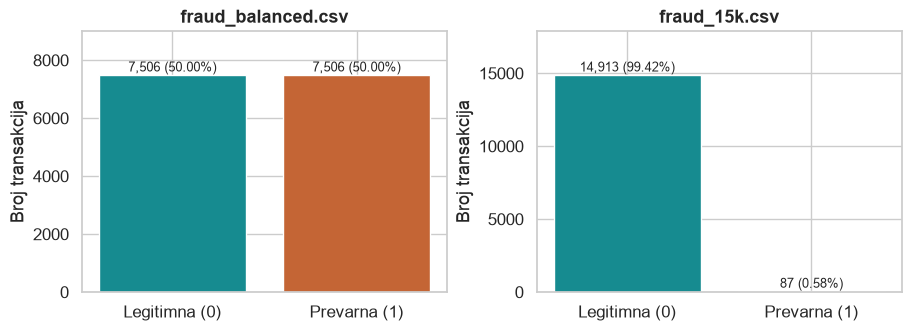

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), constrained_layout=True)
for ax, (name, data) in zip(axes, sources.items()):
    counts = data.is_fraud.value_counts().reindex([0,1])
    ax.bar([CLASS[0], CLASS[1]], counts, color=[COLORS[0],COLORS[1]])
    for i, n in enumerate(counts):
        ax.text(i, n, f'{n:,} ({100*n/len(data):.2f}%)', ha='center', va='bottom', fontsize=9)
    ax.set(title=name, ylabel='Broj transakcija', ylim=(0, counts.max()*1.2))
show_plot(fig, 'raspodjela_klasa.png')

### Datumi i izvedene veličine

Iz tekstualnih datuma izvodimo starost, sat, dan u sedmici i mjesec; iz koordinata udaljenost zračnom linijom. Starost računamo jednako u analizi i pripremi, bez zaokruživanja podataka.

In [6]:
eda['hour'] = eda['trans_datetime'].dt.hour
eda['day_of_week'] = eda['trans_datetime'].dt.day_of_week
eda['month'] = eda['trans_datetime'].dt.month
eda['age_years'] = (eda['trans_datetime'] - eda['birth_datetime']).dt.total_seconds() / (86400 * 365.2425)
lat1, lon1, lat2, lon2 = [np.radians(eda[c].to_numpy()) for c in ['lat', 'long', 'merch_lat', 'merch_long']]
a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
eda['distance_km'] = 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
eda['unix_offset_days'] = (eda['trans_datetime'] - eda['unix_datetime']).dt.total_seconds() / 86400

date_summary = {
    c: {'min': str(eda[c].min()), 'max': str(eda[c].max()), 'unique': int(eda[c].nunique())}
    for c in ['trans_datetime', 'birth_datetime', 'unix_datetime']
}
offsets = eda['unix_offset_days'].value_counts().sort_index()
date_summary['unix_offset_days_counts'] = {str(int(k)): int(v) for k, v in offsets.items()}
date_summary['seven_calendar_years_match'] = int((eda['unix_datetime'] + pd.DateOffset(years=7)).eq(eda['trans_datetime']).sum())
derived = ['age_years', 'hour', 'day_of_week', 'month', 'distance_km']
derived_stats = eda[derived].describe().T
temporal_tables = {}
for c in ['hour', 'day_of_week', 'month']:
    tab = eda.groupby(c)['is_fraud'].agg(broj='size', prevare='sum', udio_prevara='mean')
    temporal_tables[c] = tab
monthly = eda.groupby([eda['trans_datetime'].dt.to_period('M'), 'is_fraud']).size().unstack(fill_value=0)

date_view = pd.DataFrame({
    'Datum transakcije': date_summary['trans_datetime'],
    'Datum rođenja': date_summary['birth_datetime'],
    'Datum dobijen iz unix_time': date_summary['unix_datetime']
}).T.rename(columns={'min': 'Najranije', 'max': 'Najkasnije', 'unique': 'Različitih vremena/datuma'})
display(date_view)

# Starost je u godinama, a udaljenost zračnom linijom u kilometrima.
display(derived_stats.loc[['age_years', 'distance_km']].rename(index={
    'age_years': 'Starost (godine)', 'distance_km': 'Udaljenost (km)'
}, columns={
    'count': 'Broj', 'mean': 'Prosjek', 'std': 'Std. dev.', 'min': 'Minimum',
    '25%': 'Q1', '50%': 'Medijan', '75%': 'Q3', 'max': 'Maksimum'
}).round(2))
display(eda.groupby('is_fraud')[['age_years', 'distance_km']].agg(['mean', 'median', 'std']).rename(
    index=CLASS, columns={
        'age_years': 'Starost (godine)', 'distance_km': 'Udaljenost (km)',
        'mean': 'Prosjek', 'median': 'Medijan', 'std': 'Std. dev.'
    }).round(2))

# Godišnji periodi nisu jednako dugi; ovo su brojevi transakcija, ne rizik prevare.
year_counts = eda['trans_datetime'].dt.year.value_counts().sort_index()
year_counts.index.name = 'Godina'
display(year_counts.rename('Broj transakcija').to_frame())
display(Markdown(
    f'**Provjera zapisa vremena:** Unix datum + 7 kalendarskih godina '
    f'odgovara datumu transakcije u **{date_summary["seven_calendar_years_match"]} '
    f'od {len(eda)} redova**.'
))

,Najranije,Najkasnije,Različitih vremena/datuma
Datum transakcije,2019-01-01 07:11:55,2020-06-21 11:11:31,15006
Datum rođenja,1924-10-30 00:00:00,2005-01-29 00:00:00,962
Datum dobijen iz unix_time,2012-01-01 07:11:55,2013-06-21 11:11:31,15006


,Broj,Prosjek,Std. dev.,Minimum,Q1,Medijan,Q3,Maksimum
Starost (godine),15012.000,47.570,18.060,13.990,33.050,46.050,59.160,95.480
Udaljenost (km),15012.000,76.380,28.850,0.740,55.720,78.390,98.750,144.520


Starost (godine)                   Udaljenost (km)          \
                       Prosjek Medijan Std. dev.         Prosjek Medijan   
is_fraud                                                                   
Legitimna (0)           46.340  44.450    17.120          76.490  78.810   
Prevarna (1)            48.800  47.810    18.870          76.270  77.930   

                         
              Std. dev.  
is_fraud                 
Legitimna (0)    28.940  
Prevarna (1)     28.750

,Broj transakcija
Godina,
2019,10562
2020,4450


**Provjera zapisa vremena:** Unix datum + 7 kalendarskih godina odgovara datumu transakcije u **15012 od 15012 redova**.

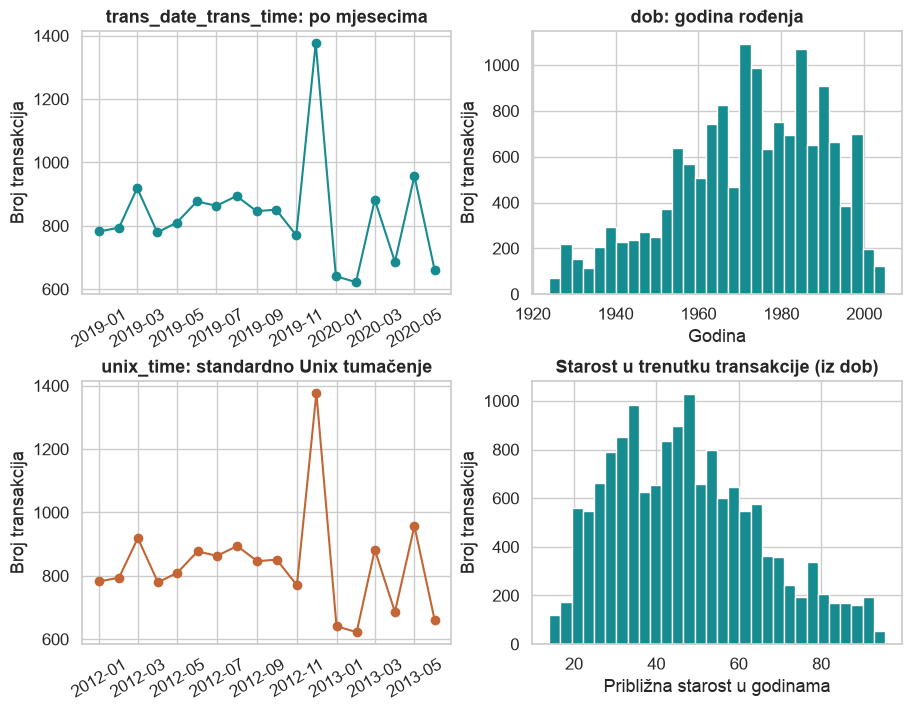

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7), constrained_layout=True)
month_counts = eda['trans_datetime'].dt.to_period('M').value_counts().sort_index()
axes[0, 0].plot(month_counts.index.to_timestamp(), month_counts, marker='o', color='#168B90')
axes[0, 0].set(title='trans_date_trans_time: po mjesecima', ylabel='Broj transakcija')
axes[0, 0].tick_params(axis='x', rotation=30)
axes[0, 1].hist(eda['birth_datetime'].dt.year, bins=30, color='#168B90', edgecolor='white')
axes[0, 1].set(title='dob: godina rođenja', xlabel='Godina', ylabel='Broj transakcija')
unix_month = eda['unix_datetime'].dt.to_period('M').value_counts().sort_index()
axes[1, 0].plot(unix_month.index.to_timestamp(), unix_month, marker='o', color='#C46535')
axes[1, 0].set(title='unix_time: standardno Unix tumačenje', ylabel='Broj transakcija')
axes[1, 0].tick_params(axis='x', rotation=30)
axes[1, 1].hist(eda['age_years'], bins=30, color='#168B90', edgecolor='white')
axes[1, 1].set(title='Starost u trenutku transakcije (iz dob)', xlabel='Približna starost u godinama', ylabel='Broj transakcija')
show_plot(fig, 'datumi.png')

Tekstualni datumi pokrivaju 1.1.2019.–21.6.2020., dok standardno tumačenje `unix_time` daje 2012.–2013. godinu. Dodavanje sedam kalendarskih godina usklađuje svih 15.012 redova. Zato vremenske karakteristike izvodimo iz tekstualnog datuma, a `unix_time` izostavljamo iz pripreme. Posljednji mjesec je nepotpun. Starost se broji po transakcijama, a ne po jedinstvenim osobama.

### Numeričke raspodjele, smaknutost, gustoća i outlieri

Obuhvatamo **svih sedam izvornih numeričkih varijabli**, uključujući `unix_time`, te svih pet izvedenih numeričkih veličina. Za svaku računamo sredinu, standardnu devijaciju, kvartile, minimum, maksimum, `skew` i broj vrijednosti izvan 1,5 × IQR.

|skew| ≤ 0,5 označava približnu simetriju; 0,5 < |skew| ≤ 1 umjerenu, a |skew| > 1 jaku asimetriju. Pragovi pomažu opisu i sami ne nalažu transformaciju. **Standardizacija mijenja skalu, ali ne uklanja asimetriju.**

In [8]:
def skew_description(value):
    if abs(value) <= .5: return 'približno simetrična'
    if abs(value) <= 1: return 'umjerena asimetrija'
    return 'jaka asimetrija'

def numeric_profile(data, columns):
    table = data[columns].describe().T
    table['skew'] = data[columns].skew()
    q1, q3 = data[columns].quantile(.25), data[columns].quantile(.75)
    table['iqr_low'] = q1 - 1.5 * (q3-q1)
    table['iqr_high'] = q3 + 1.5 * (q3-q1)
    outside = data[columns].lt(table.iqr_low, axis=1) | data[columns].gt(table.iqr_high, axis=1)
    table['outlier_count'] = outside.sum().astype(int)
    table['outlier_pct'] = 100 * outside.mean()
    table['oblik'] = table['skew'].map(skew_description)
    table.index.name = 'atribut'
    return table

numeric_columns = continuous + ['age_years', 'distance_km', 'hour', 'day_of_week', 'month']
numeric_stats = numeric_profile(eda, numeric_columns)
display(numeric_stats[['count','mean','std','min','25%','50%','75%','max','skew','oblik','outlier_count','outlier_pct']])

,count,mean,std,min,25%,50%,75%,max,skew,oblik,outlier_count,outlier_pct
atribut,,,,,,,,,,,,
amt,15012.000,299.518,373.916,1.000,20.497,89.545,477.103,6337.250,1.478,jaka asimetrija,118,0.786
lat,15012.000,38.620,5.129,20.027,34.779,39.406,42.016,66.693,0.026,približno simetrična,66,0.440
long,15012.000,-90.275,14.085,-165.672,-96.984,-87.410,-80.128,-67.950,-1.196,jaka asimetrija,491,3.271
city_pop,15012.000,90510.747,303554.430,23.000,743.000,2526.000,21125.000,2906700.000,5.622,jaka asimetrija,2774,18.479
unix_time,15012.000,1348818366.248,13325733.333,1325401915.000,1337471412.000,1348875677.000,1359843757.250,1371813091.000,0.004,približno simetrična,0,0.000
merch_lat,15012.000,38.612,5.168,19.042,34.897,39.403,41.991,67.510,0.029,približno simetrična,79,0.526
merch_long,15012.000,-90.275,14.105,-166.551,-96.990,-87.360,-80.169,-67.027,-1.193,jaka asimetrija,480,3.197
age_years,15012.000,47.566,18.059,13.993,33.049,46.046,59.158,95.484,0.481,približno simetrična,0,0.000
distance_km,15012.000,76.378,28.847,0.739,55.716,78.389,98.752,144.523,-0.241,približno simetrična,0,0.000


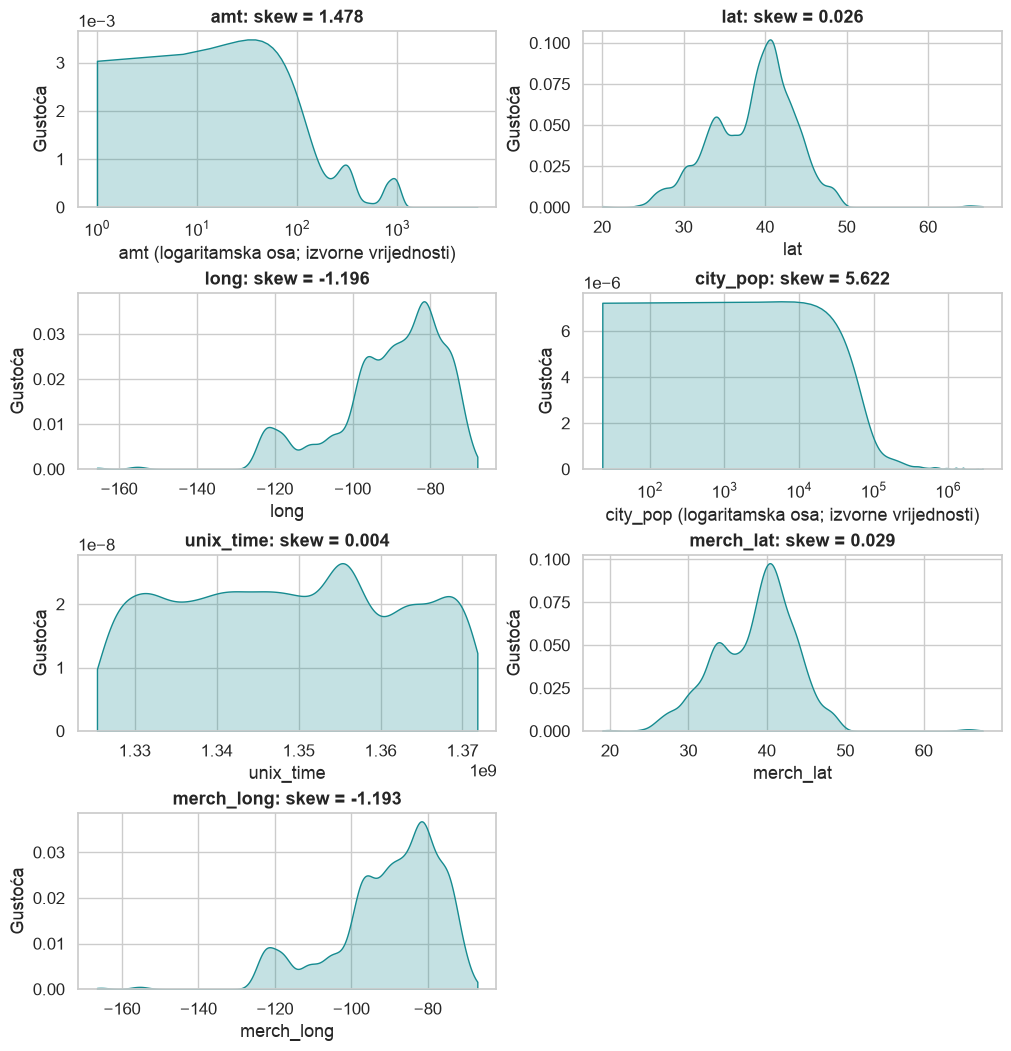

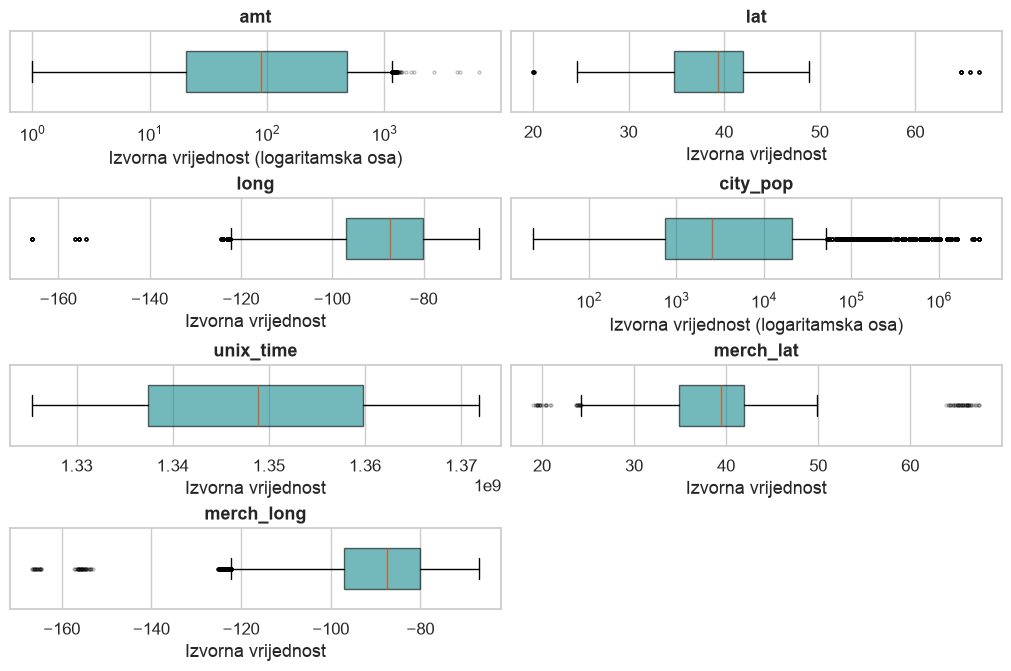

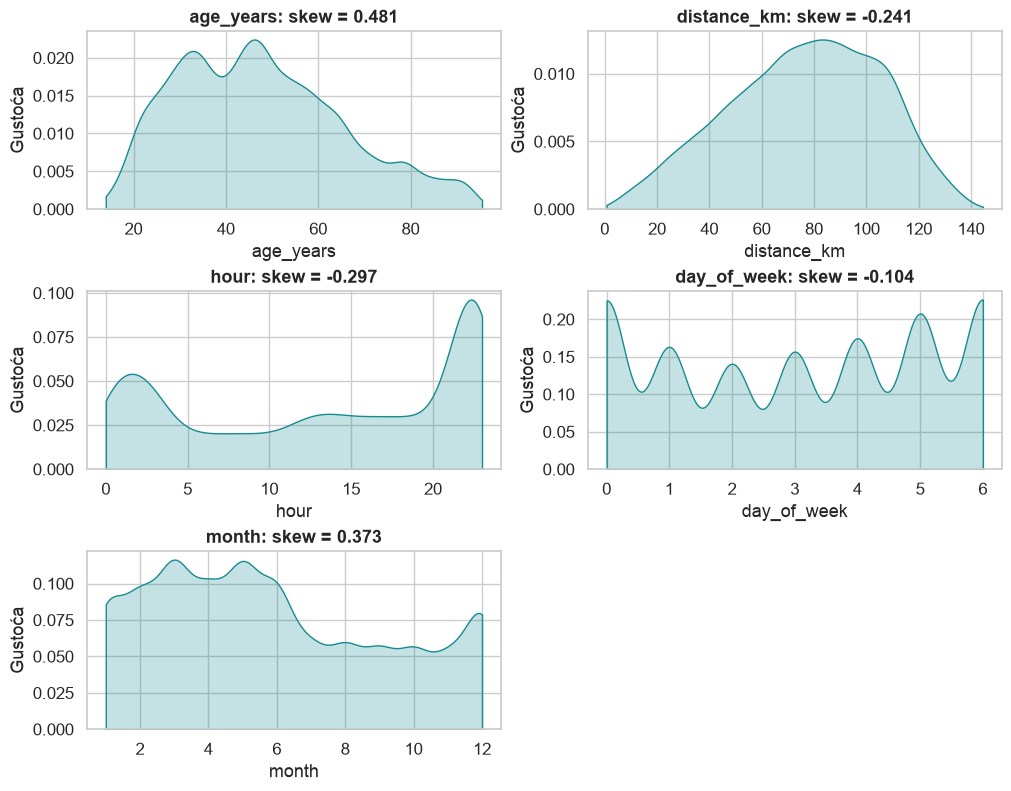

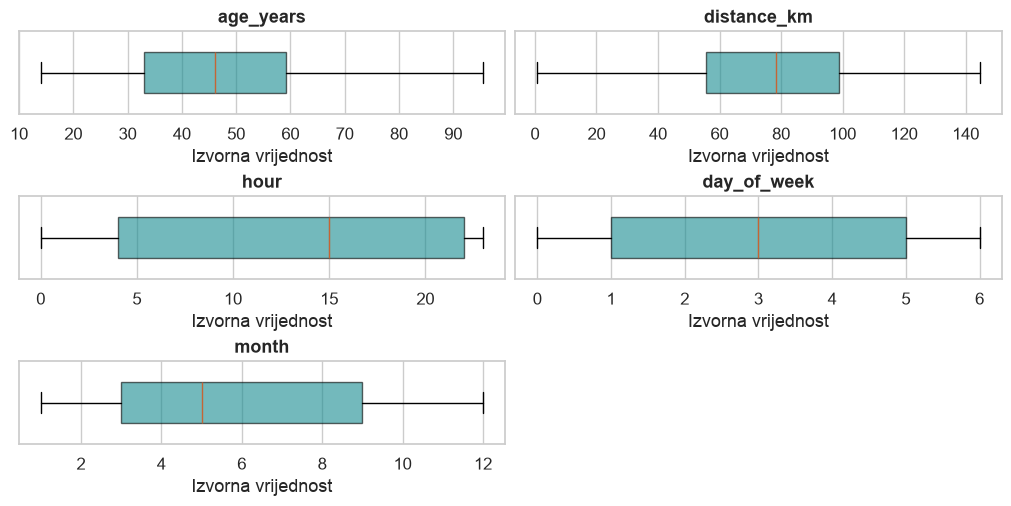

In [9]:
from matplotlib.ticker import ScalarFormatter

def numeric_plots(data, columns, density_file, box_file, log_axes=()):
    nrows = (len(columns) + 1) // 2
    fig, axes = plt.subplots(nrows, 2, figsize=(10, 2.6*nrows), constrained_layout=True, squeeze=False)
    for ax, c in zip(axes.flat, columns):
        values = data[c].dropna()
        sns.kdeplot(x=values, ax=ax, fill=True, cut=0, gridsize=1024, color=COLORS[0])
        if c in log_axes:
            ax.set_xscale('log')
        ax.set_title(f'{c}: skew = {values.skew():.3f}')
        ax.set_xlabel(c + (' (logaritamska osa; izvorne vrijednosti)' if c in log_axes else ''))
        ax.set_ylabel('Gustoća')
        ax.ticklabel_format(axis='y', style='sci', scilimits=(-3,3))
    for ax in list(axes.flat)[len(columns):]: ax.set_visible(False)
    show_plot(fig, density_file)

    fig, axes = plt.subplots(nrows, 2, figsize=(10, 1.65*nrows), constrained_layout=True, squeeze=False)
    for ax, c in zip(axes.flat, columns):
        ax.boxplot(data[c].dropna(), orientation='horizontal', widths=.5,
                   flierprops={'markersize':2, 'alpha':.25}, patch_artist=True,
                   boxprops={'facecolor':COLORS[0], 'alpha':.6})
        if c in log_axes: ax.set_xscale('log')
        ax.set(title=c, xlabel='Izvorna vrijednost' + (' (logaritamska osa)' if c in log_axes else ''))
        ax.set_yticks([])
    for ax in list(axes.flat)[len(columns):]: ax.set_visible(False)
    show_plot(fig, box_file)

numeric_plots(eda, continuous, 'numericke_gustoce.png', 'numericki_boxplotovi.png', ['amt','city_pop'])
numeric_plots(eda, numeric_columns[7:], 'izvedene_gustoce.png', 'izvedeni_boxplotovi.png')

Gustoća (KDE) opisuje izglađeni oblik raspodjele; visina krive nije broj transakcija. Za sat, dan i mjesec to je pomoćni prikaz diskretnih veličina, koje prikazujemo i frekvencijama. Logaritamska osa iznosa i populacije samo olakšava čitanje izvornog raspona; stvarnu transformaciju provjeravamo zasebno.

`amt` (skew ≈ 1,48) i `city_pop` (≈ 5,62) imaju izražene desne repove. `long` i `merch_long` imaju jaku lijevu asimetriju (≈ −1,20), ali opisuju raspored lokacija; ne transformišemo ih samo radi simetrije. Box plot i IQR izdvajaju ekstremne vrijednosti, ali pozitivni iznosi, veliki gradovi i dozvoljene koordinate nisu potvrđene greške. **Ne brišemo niti ograničavamo takve redove automatski.**

### Kategorije, oznake i razlike između klasa

Za svih 12 tekstualnih i kategoričkih kolona računamo potpune frekvencije, broj kategorija i udio prevara u kategoriji. U grafikonima prikazujemo najčešće vrijednosti; identifikatore posmatramo kao oznake.

In [10]:
category_tables = {}
category_summary = []
for c in categorical:
    counts = raw.groupby(c, dropna=False)['is_fraud'].agg(broj='size', prevare='sum', udio_prevara='mean')
    counts['udio_pct'] = 100 * counts['broj'] / len(raw)
    counts = counts.sort_values('broj', ascending=False)
    counts.index.name = c
    category_tables[c] = counts
    top = counts.iloc[0]
    category_summary.append({'atribut': c, 'broj_kategorija': len(counts),
                             'najcesca_vrijednost': str(counts.index[0]),
                             'najcesca_broj': int(top['broj']), 'najcesca_pct': float(top['udio_pct']),
                             'jednokratne_kategorije': int(counts['broj'].eq(1).sum())})
category_summary = pd.DataFrame(category_summary)

display(category_summary.rename(columns={
    'atribut': 'Kolona', 'broj_kategorija': 'Različitih vrijednosti',
    'najcesca_vrijednost': 'Najčešća vrijednost', 'najcesca_broj': 'Broj transakcija',
    'najcesca_pct': 'Udio u skupu (%)', 'jednokratne_kategorije': 'Vrijednosti sa samo 1 transakcijom'
}).round(2))

,Kolona,Različitih vrijednosti,Najčešća vrijednost,Broj transakcija,Udio u skupu (%),Vrijednosti sa samo 1 transakcijom
0,cc_num,977,630451534402,38,0.250,10
1,merchant,693,fraud_Kilback LLC,72,0.480,0
2,category,14,grocery_pos,2494,16.610,0
3,first,352,Christopher,330,2.200,2
4,last,480,Smith,301,2.010,4
5,gender,2,F,7835,52.190,0
6,street,977,561 Little Plain Apt. 738,38,0.250,10
7,city,889,Warren,57,0.380,10
8,state,51,TX,1024,6.820,0
9,zip,964,82514,45,0.300,10


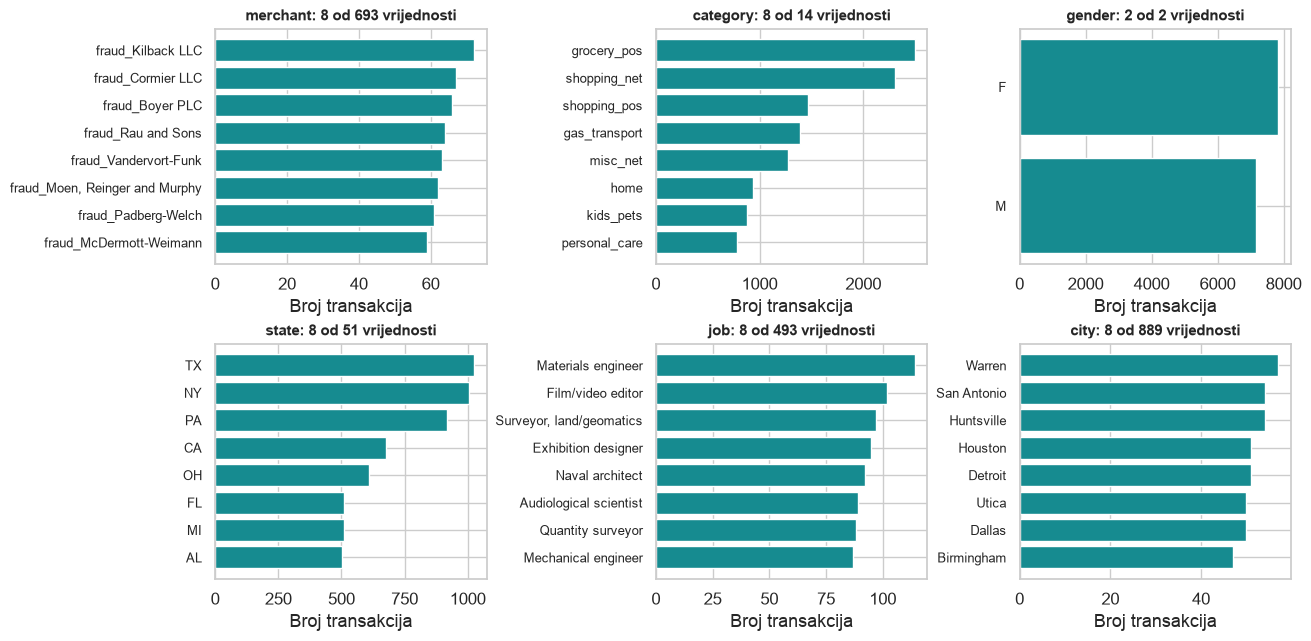

In [11]:
def top_categories(ax, c):
    values = category_tables[c]['broj'].head(8).iloc[::-1]
    labels = [str(v) if len(str(v)) <= 30 else str(v)[:27]+'…' for v in values.index]
    ax.barh(labels, values.to_numpy(), color='#168B90')
    ax.set_title(f'{c}: {len(values)} od {len(category_tables[c])} vrijednosti', fontsize=10.5)
    ax.set_xlabel('Broj transakcija')
    ax.tick_params(axis='y', labelsize=9.5)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.3), constrained_layout=True)
for ax, c in zip(axes.flat, ['merchant', 'category', 'gender', 'state', 'job', 'city']):
    top_categories(ax, c)
show_plot(fig, 'kategoricke_distribucije.png')

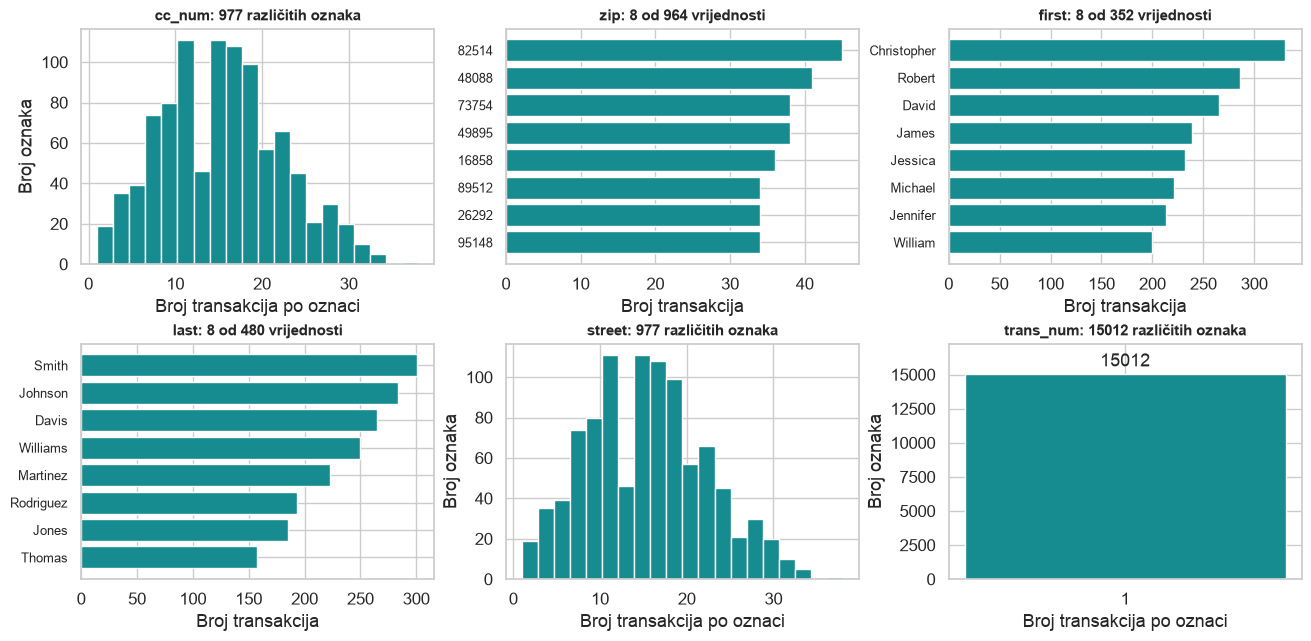

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.3), constrained_layout=True)
for ax, c in zip(axes.flat, ['cc_num', 'zip', 'first', 'last', 'street', 'trans_num']):
    if c in ['cc_num', 'street', 'trans_num']:
        frequencies = category_tables[c]['broj']
        if frequencies.nunique() == 1:
            bars = ax.bar([int(frequencies.iloc[0])], [len(frequencies)], width=.5, color='#168B90')
            ax.bar_label(bars, padding=3)
            ax.set_xticks([int(frequencies.iloc[0])])
            ax.set_ylim(0, len(frequencies)*1.15)
        else:
            ax.hist(frequencies, bins=20, color='#168B90', edgecolor='white')
        ax.set_title(f'{c}: {len(frequencies)} različitih oznaka', fontsize=10.5)
        ax.set_xlabel('Broj transakcija po oznaci')
        ax.set_ylabel('Broj oznaka')
    else:
        top_categories(ax, c)
show_plot(fig, 'identifikatori.png')

Postoje 693 trgovca, 14 kategorija kupovine i 977 kartica. Prefiks `fraud_` pojavljuje se kod svih trgovaca i ne označava klasu. Imena, adrese i kartice ponavljaju se; njihov numerički zapis ne daje ordinalno značenje. Sve ove oznake imaju nominalno značenje. U 1.4 grad i poštanski broj izostavljamo zbog velikog broja kategorija i preklapanja s koordinatama; za trgovca i zanimanje grupišemo rijetke kategorije prije one-hot kodiranja.

In [13]:
amount_by_class = raw.groupby('is_fraud')['amt'].agg(['count', 'mean', 'std', 'median', 'min', 'max'])
display(amount_by_class.rename(index=CLASS, columns={
    'count': 'Broj', 'mean': 'Prosjek USD', 'std': 'Std. dev. USD',
    'median': 'Medijan USD', 'min': 'Minimum USD', 'max': 'Maksimum USD'
}).round(2))

,Broj,Prosjek USD,Std. dev. USD,Medijan USD,Minimum USD,Maksimum USD
is_fraud,,,,,,
Legitimna (0),7506,67.720,140.100,47.920,1.000,6337.250
Prevarna (1),7506,531.320,390.560,396.500,1.060,1376.040


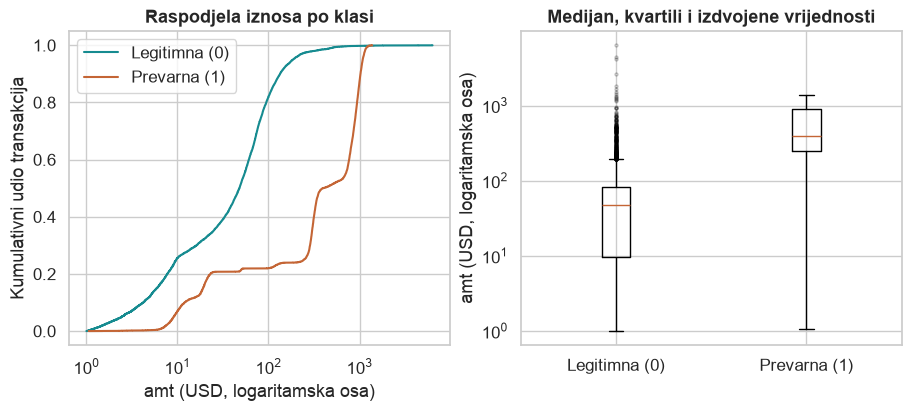

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for label, group in eda.groupby('is_fraud'):
    values = np.sort(group['amt'].to_numpy())
    axes[0].step(values, np.arange(1, len(values)+1)/len(values), where='post',
                 label=CLASS[label], color=COLORS[label])
axes[0].set_xscale('log')
axes[0].set(xlabel='amt (USD, logaritamska osa)', ylabel='Kumulativni udio transakcija', title='Raspodjela iznosa po klasi')
axes[0].legend()
axes[1].boxplot([eda.loc[eda.is_fraud.eq(label), 'amt'] for label in [0, 1]],
                tick_labels=[CLASS[0], CLASS[1]], showfliers=True,
                flierprops={'markersize': 2, 'alpha': .25})
axes[1].set_yscale('log')
axes[1].set(ylabel='amt (USD, logaritamska osa)', title='Medijan, kvartili i izdvojene vrijednosti')
show_plot(fig, 'iznos_po_klasi.png')

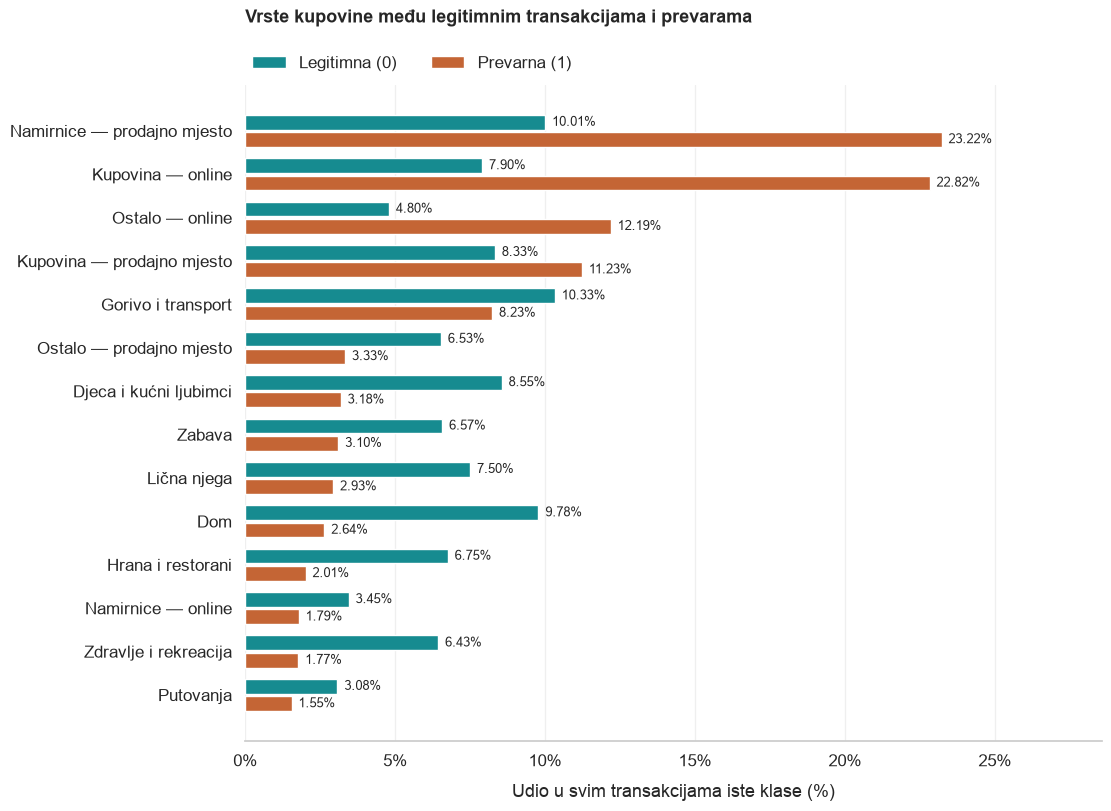

In [15]:
from matplotlib.ticker import PercentFormatter

# Nazive prevodimo samo za prikaz; originalni podaci ostaju isti.
category_labels = {
    'grocery_pos': 'Namirnice — prodajno mjesto',
    'grocery_net': 'Namirnice — online',
    'shopping_pos': 'Kupovina — prodajno mjesto',
    'shopping_net': 'Kupovina — online',
    'misc_pos': 'Ostalo — prodajno mjesto',
    'misc_net': 'Ostalo — online',
    'gas_transport': 'Gorivo i transport',
    'kids_pets': 'Djeca i kućni ljubimci',
    'entertainment': 'Zabava',
    'personal_care': 'Lična njega',
    'home': 'Dom',
    'food_dining': 'Hrana i restorani',
    'health_fitness': 'Zdravlje i rekreacija',
    'travel': 'Putovanja',
}

# Svaku klasu zasebno posmatramo kao 100%.
category_mix = pd.crosstab(
    eda['category'], eda['is_fraud'], normalize='columns'
).mul(100).sort_values(1, ascending=False)

fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
y = np.arange(len(category_mix))
for label, offset in [(0, -.2), (1, .2)]:
    bars = ax.barh(
        y + offset, category_mix[label], height=.34,
        label=CLASS[label], color=COLORS[label]
    )
    ax.bar_label(bars, labels=[f'{value:.2f}%' for value in category_mix[label]],
                 padding=5, fontsize=9)

ax.set_yticks(y, [category_labels.get(c, c) for c in category_mix.index])
ax.invert_yaxis()
ax.set_xlim(0, category_mix.to_numpy().max() * 1.23)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set_xlabel('Udio u svim transakcijama iste klase (%)', labelpad=10)
ax.set_title('Vrste kupovine među legitimnim transakcijama i prevarama',
             loc='left', pad=45, fontsize=13)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.01), ncol=2,
          frameon=False, borderaxespad=0)
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=.3)
ax.grid(axis='y', visible=False)
sns.despine(ax=ax, left=True)
show_plot(fig, 'kategorije_po_klasi.png')

In [16]:
category_frequencies = category_tables['category'][['broj', 'prevare']].copy()
category_frequencies['legitimne'] = category_frequencies['broj'] - category_frequencies['prevare']
category_frequencies['udio_prevara_pct'] = (
    100 * category_frequencies['prevare'] / category_frequencies['broj']
)
category_frequencies = category_frequencies.sort_values('udio_prevara_pct', ascending=False)
category_view = category_frequencies.rename(index=category_labels).rename(columns={
    'broj': 'Ukupno transakcija',
    'legitimne': 'Legitimne',
    'prevare': 'Prevare',
    'udio_prevara_pct': 'Prevare u kategoriji (%)'
})[['Ukupno transakcija', 'Legitimne', 'Prevare', 'Prevare u kategoriji (%)']]
category_view.index.name = 'Vrsta kupovine'
display(category_view.style.format({
    'Ukupno transakcija': '{:,.0f}', 'Legitimne': '{:,.0f}',
    'Prevare': '{:,.0f}', 'Prevare u kategoriji (%)': '{:.2f}%'
}, thousands=' '))

,Ukupno transakcija,Legitimne,Prevare,Prevare u kategoriji (%)
Vrsta kupovine,,,,
Kupovina — online,2 306,593,1 713,74.28%
Ostalo — online,1 275,360,915,71.76%
Namirnice — prodajno mjesto,2 494,751,1 743,69.89%
Kupovina — prodajno mjesto,1 468,625,843,57.43%
Gorivo i transport,1 393,775,618,44.36%
Namirnice — online,393,259,134,34.10%
Ostalo — prodajno mjesto,740,490,250,33.78%
Putovanja,347,231,116,33.43%
Zabava,726,493,233,32.09%


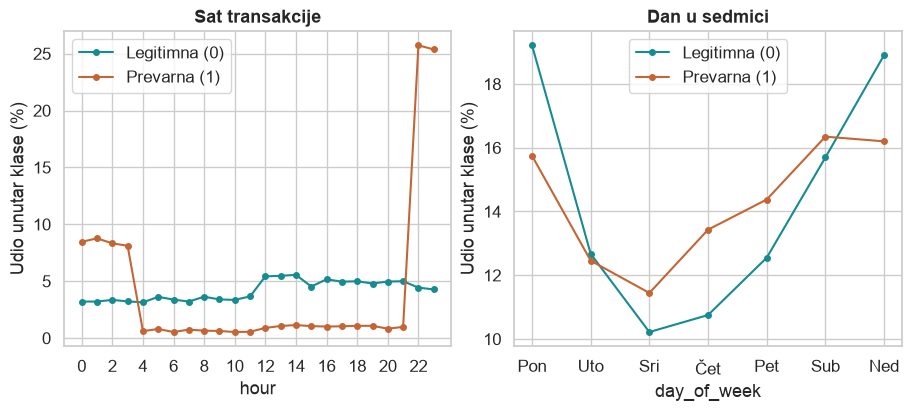

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, c, title in zip(axes, ['hour', 'day_of_week'], ['Sat transakcije', 'Dan u sedmici']):
    normalized = pd.crosstab(eda[c], eda['is_fraud'], normalize='columns') * 100
    for label in [0, 1]:
        ax.plot(normalized.index, normalized[label], marker='o', markersize=4, label=CLASS[label], color=COLORS[label])
    ax.set(title=title, ylabel='Udio unutar klase (%)', xlabel=c)
    if c == 'hour':
        ax.set_xticks(range(0, 24, 2))
    else:
        ax.set_xticks(range(7), ['Pon', 'Uto', 'Sri', 'Čet', 'Pet', 'Sub', 'Ned'])
    ax.legend()
show_plot(fig, 'vremenski_obrasci.png')

In [18]:
night = eda['hour'].isin([22, 23, 0, 1, 2, 3])
night_share = eda.assign(night=night).groupby('is_fraud')['night'].mean() * 100
display(night_share.rename(index=CLASS).rename('Transakcije od 22:00 do 03:59 (%)').round(2).to_frame())

,Transakcije od 22:00 do 03:59 (%)
is_fraud,
Legitimna (0),21.720
Prevarna (1),84.760


Medijan iznosa je 47,92 USD za legitimne i 396,50 USD za prevarne transakcije, uz preklapanje raspodjela. Najveći iznos pripada legitimnoj transakciji. Od 22:00 do 03:59 dešava se 84,76% svih prevara, naspram 21,72% legitimnih transakcija. Kategorije `grocery_pos` i `shopping_net` najzastupljenije su među prevarama. Procenti unutar balansiranog uzorka ne predstavljaju procjenu stvarnog rizika.

### Povezanost numeričkih varijabli

Pearsonov koeficijent opisuje linearnu, a Spearmanov povezanost rangova. Identifikatori nisu uključeni. Kod cikličnih veličina, npr. sata, mala korelacija ne isključuje izražen vremenski obrazac.

In [19]:
corr_columns = numeric_columns + ['is_fraud']
pearson = eda[corr_columns].corr(method='pearson')
spearman = eda[corr_columns].corr(method='spearman')
correlation_target = pd.DataFrame({'pearson': pearson['is_fraud'].drop('is_fraud'),
                                    'spearman': spearman['is_fraud'].drop('is_fraud')})

display(correlation_target.rename(columns={'pearson': 'Pearson', 'spearman': 'Spearman'}).round(2))
display(pd.DataFrame({
    'Par kolona': ['lat i merch_lat', 'long i merch_long'],
    'Pearson': [pearson.loc['lat', 'merch_lat'], pearson.loc['long', 'merch_long']]
}).round(2))

,Pearson,Spearman
amt,0.620,0.580
lat,0.010,0.000
long,0.030,0.040
city_pop,0.020,0.010
unix_time,-0.030,-0.030
merch_lat,0.010,0.000
merch_long,0.030,0.040
age_years,0.070,0.060
distance_km,-0.000,-0.010
hour,0.090,0.160


,Par kolona,Pearson
0,lat i merch_lat,0.990
1,long i merch_long,1.000


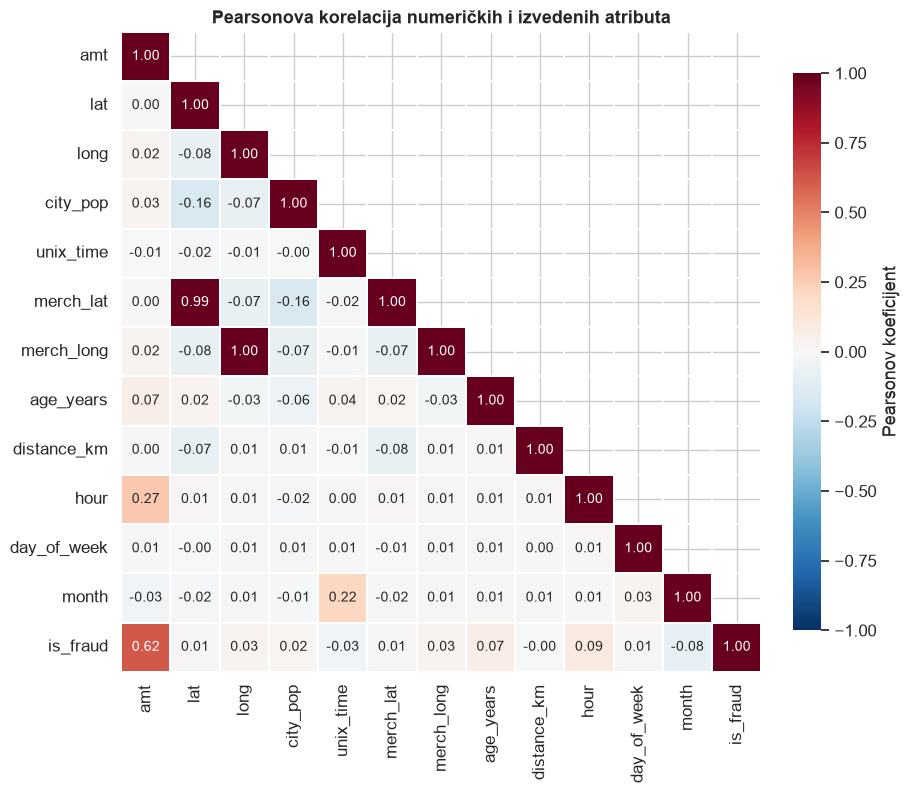

In [20]:
fig, ax = plt.subplots(figsize=(9, 8), constrained_layout=True)
mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)
sns.heatmap(pearson, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=.3, annot_kws={'size':10}, ax=ax,
            cbar_kws={'label':'Pearsonov koeficijent', 'shrink':.8})
ax.set_title('Pearsonova korelacija numeričkih i izvedenih atributa')
show_plot(fig, 'korelacije.png')

Iznos ima najveću pojedinačnu numeričku povezanost s klasom (Pearson ≈ 0,62; Spearman ≈ 0,58). Koordinate korisnika i trgovca su snažno povezane (≈ 0,99 za širinu i ≈ 1,00 za dužinu, nakon zaokruživanja). U pripremi zadržavamo koordinate korisnika i izvedenu udaljenost, a izostavljamo dvije redundantne koordinate trgovca. Korelacija sama ne dokazuje uzročnost.

### Detaljni profili, rijetke kategorije i geografsko preklapanje

Prikazujemo pojedinačne numeričke raspodjele, IQR izdvajanja po klasama, frekvencije rijetkih kategorija i broj lokacija po geografskim oznakama. Pragove grupisanja poređujemo samo prema frekvencijama, bez procjene uspješnosti. Slike lokacija predstavljaju raspored simuliranih transakcija.

,Atribut,Kategorija,Najčešća,Najviše redova,Kategorija ispod 10,Redova ispod 10,Top 10 (%)
0,merchant,693,fraud_Kilback LLC,72,104,691,4.190
1,category,14,grocery_pos,2494,0,0,86.584
2,gender,2,F,7835,0,0,100.000
3,city,889,Warren,57,172,1061,3.384
4,state,51,TX,1024,1,9,44.278
5,zip,964,82514,45,203,1259,2.445
6,job,493,Materials engineer,114,44,286,6.208


,Atribut,Prag,Zasebne kategorije,Grupisane kategorije,Redova u grupi,Zasebno očuvano (%)
0,merchant,10,671,22,173,99.228
1,merchant,20,551,142,1983,91.155
2,merchant,30,332,361,7439,66.818
3,merchant,50,106,587,15915,29.011
4,job,10,475,19,127,99.434
5,job,20,396,98,1280,94.291
6,job,30,315,179,3290,85.325
7,job,50,179,315,8569,61.778


,Atribut,Klasa,Izdvojeno,Udio klase (%)
0,amt,0,13,0.173
1,amt,1,105,1.399
2,lat,0,23,0.306
3,lat,1,43,0.573
4,long,0,250,3.331
5,long,1,241,3.211
6,city_pop,0,1354,18.039
7,city_pop,1,1420,18.918
8,unix_time,0,0,0.000
9,unix_time,1,0,0.000


,Oznaka,Različitih oznaka,Medijan širina po oznaci,Medijan kartica po oznaci
0,city,889,1.000,1.000
1,zip,964,1.000,1.000
2,state,51,17.000,17.000


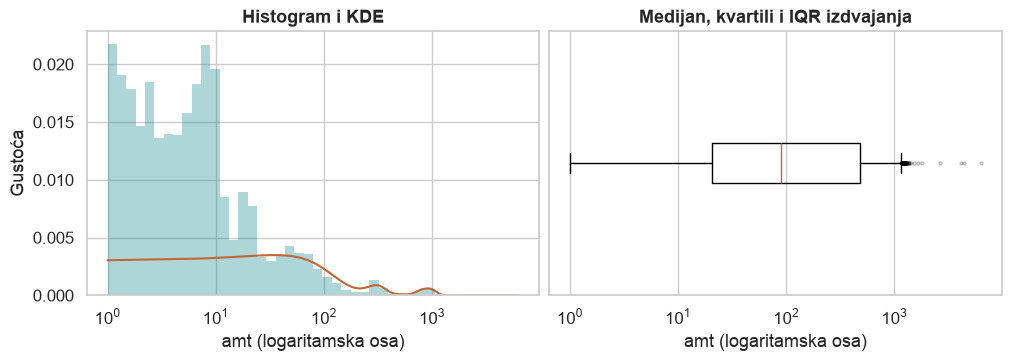

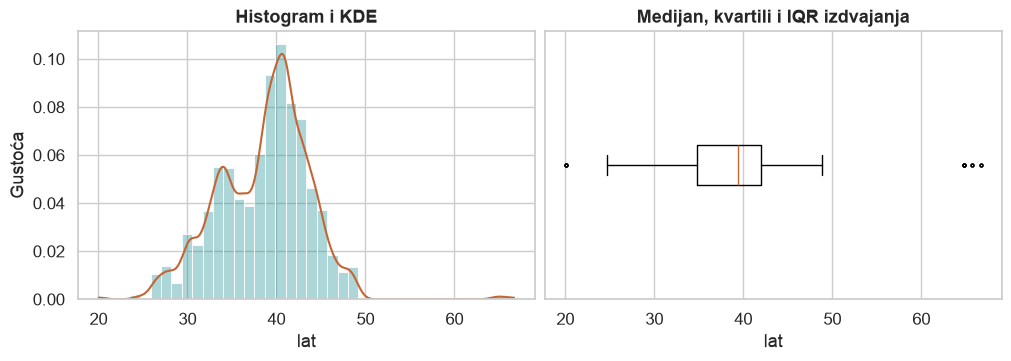

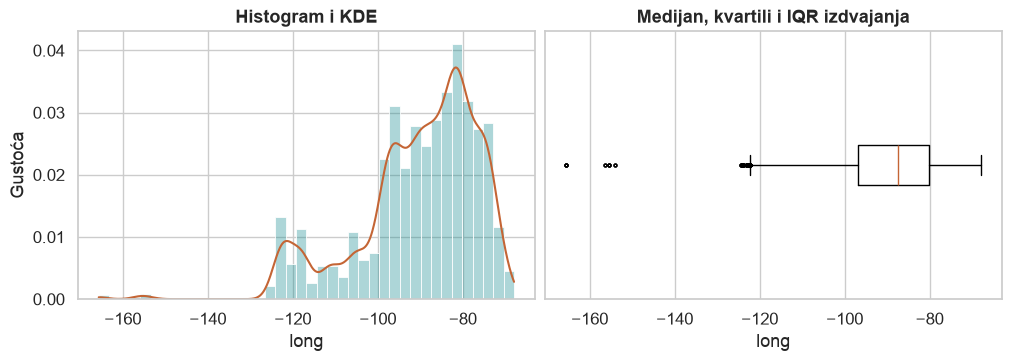

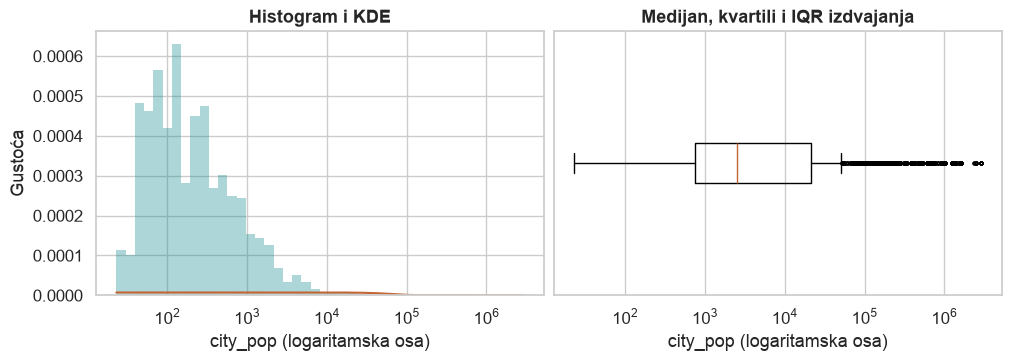

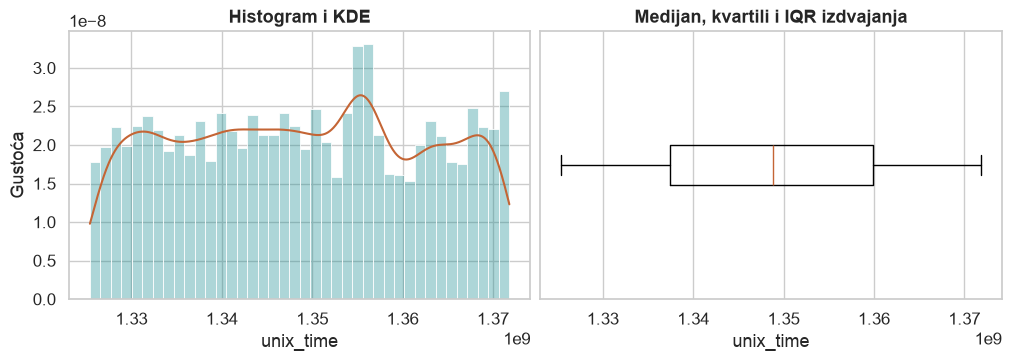

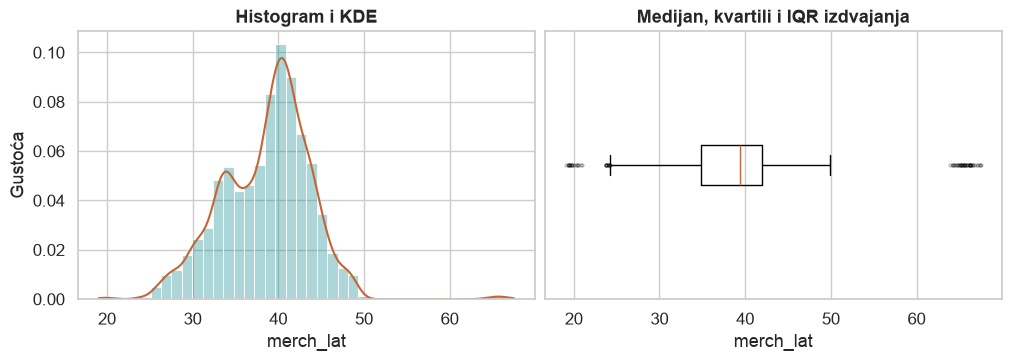

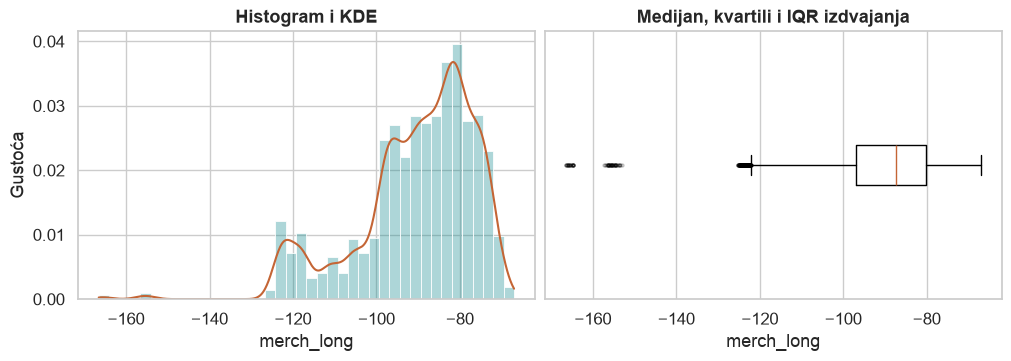

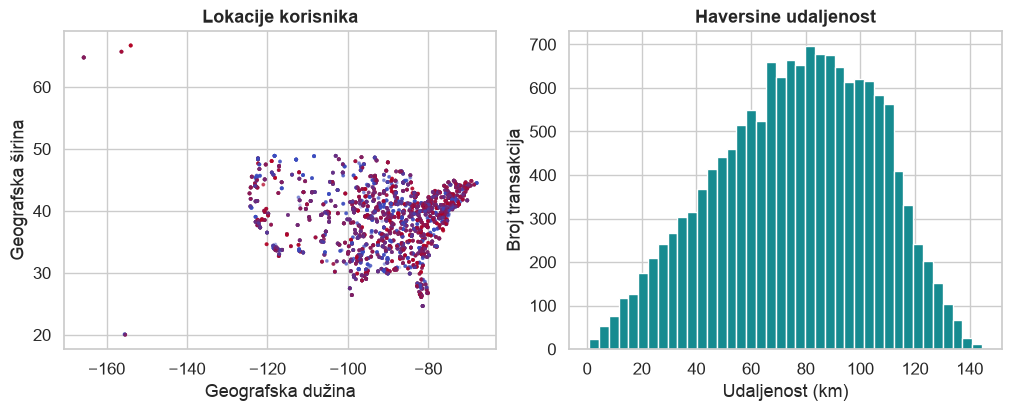

In [21]:
# Frekvencije kategorija, numerički profili i geografske provjere.
reference_raw = pd.concat(list(sources.values()),ignore_index=True).drop_duplicates('trans_num')
category_diagnostics=[]
threshold_rows=[]
for c in ['merchant','category','gender','city','state','zip','job']:
    counts=raw[c].value_counts()
    category_diagnostics.append({'Atribut':c,'Kategorija':len(counts),'Najčešća':counts.index[0],
        'Najviše redova':int(counts.iloc[0]),'Kategorija ispod 10':int((counts<10).sum()),
        'Redova ispod 10':int(counts[counts<10].sum()),'Top 10 (%)':100*counts.head(10).sum()/len(raw)})
    if c in ['merchant','job']:
        v=reference_raw[c].value_counts()
        for threshold in [10,20,30,50]:
            threshold_rows.append({'Atribut':c,'Prag':threshold,'Zasebne kategorije':int((v>=threshold).sum()),
                'Grupisane kategorije':int((v<threshold).sum()),'Redova u grupi':int(v[v<threshold].sum()),
                'Zasebno očuvano (%)':100*v[v>=threshold].sum()/len(reference_raw)})
category_diagnostics=pd.DataFrame(category_diagnostics)
threshold_summary=pd.DataFrame(threshold_rows)
display(category_diagnostics)
display(threshold_summary)

outlier_class=[]
for c in continuous:
    lo,hi=numeric_stats.loc[c,['iqr_low','iqr_high']]
    mask=(raw[c]<lo)|(raw[c]>hi)
    for cls in [0,1]:
        group=raw.is_fraud.eq(cls)
        outlier_class.append({'Atribut':c,'Klasa':cls,'Izdvojeno':int((mask&group).sum()),
                              'Udio klase (%)':100*(mask&group).sum()/group.sum()})
outlier_class=pd.DataFrame(outlier_class)
display(outlier_class)

geo_details=pd.DataFrame([
    {'Oznaka':c,'Različitih oznaka':raw[c].nunique(),
     'Medijan širina po oznaci':raw.groupby(c).lat.nunique().median(),
     'Medijan kartica po oznaci':raw.groupby(c).cc_num.nunique().median()}
    for c in ['city','zip','state']])
display(geo_details)

# Pojedinačni prikazi svih izvornih numeričkih varijabli: histogram, KDE i box plot.
for c in continuous:
    values=raw[c]
    fig,axes=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
    bins=np.geomspace(values.min(),values.max(),45) if c in ['amt','city_pop'] else 40
    sns.histplot(x=values,bins=bins,stat='density',ax=axes[0],color=COLORS[0],alpha=.35)
    sns.kdeplot(x=values,cut=0,gridsize=1024,ax=axes[0],color=COLORS[1])
    axes[1].boxplot(values,orientation='horizontal',flierprops={'markersize':2,'alpha':.25})
    axes[1].set_yticks([])
    for ax in axes:
        if c in ['amt','city_pop']: ax.set_xscale('log')
        ax.set_xlabel(c+(' (logaritamska osa)' if c in ['amt','city_pop'] else ''))
    axes[0].set_ylabel('Gustoća')
    axes[0].set_title('Histogram i KDE')
    axes[1].set_title('Medijan, kvartili i IQR izdvajanja')
    show_plot(fig,f'profil_{c}.png')

fig,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
axes[0].scatter(raw.long,raw.lat,c=raw.is_fraud,cmap='coolwarm',s=3,alpha=.2)
axes[0].set(xlabel='Geografska dužina',ylabel='Geografska širina',title='Lokacije korisnika')
axes[1].hist(eda.distance_km,bins=40,color=COLORS[0])
axes[1].set(xlabel='Udaljenost (km)',ylabel='Broj transakcija',title='Haversine udaljenost')
show_plot(fig,'geografski_obrasci.png')


## 1.4 Priprema i transformacija podataka

Pripremamo dva cijela skupa: balansirani (15.012 redova) i nebalansirani (15.000 redova). Ista pravila važe za obje verzije, a broj redova i odnos klasa ostaju nepromijenjeni. Priprema obuhvata izbor atributa, izvođenje smislenih veličina, transformaciju asimetričnih raspodjela, kodiranje i standardizaciju.

In [22]:
datasets = {'balanced': sources['fraud_balanced.csv'], 'unbalanced': sources['fraud_15k.csv']}
dataset_labels = {'balanced':'Balansirani', 'unbalanced':'Nebalansirani'}
target_column = 'is_fraud'

### 1.4-A Izbor i izvođenje atributa

`amt` i `city_pop` transformišemo pomoću `log1p(x) = ln(1+x)`. Iz datuma izvodimo starost i ciklične zapise sata i dana u sedmici (`sin`, `cos`), a iz koordinata udaljenost. Izostavljamo identifikatore i lične podatke, sirove datume, neusklađeni `unix_time` i dvije redundantne koordinate trgovca. Mjesec ostaje u analizi zbog nepotpunog godišnjeg obuhvata. IQR izdvajanja sama nisu razlog za brisanje redova.

`city` i `zip` se također izostavljaju: lokaciju opisuju koordinate i savezna država. Trgovca i zanimanje zadržavamo uz grupisanje kategorija s manje od 20 transakcija. Pravilo je isto za obje verzije; broj redova se ne mijenja.

In [23]:
def prepare_features(data):
    result = data.copy()
    timestamp = pd.to_datetime(result.trans_date_trans_time, format='%Y-%m-%d %H:%M:%S')
    birth = pd.to_datetime(result.dob, format='%Y-%m-%d')
    result['age_years'] = (timestamp-birth).dt.total_seconds() / (86400*365.2425)
    lat1,lon1,lat2,lon2 = [np.radians(result[c].to_numpy()) for c in ['lat','long','merch_lat','merch_long']]
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    result['distance_km'] = 6371.0088 * 2*np.arcsin(np.sqrt(np.clip(a,0,1)))
    for c, period, values in [('hour',24,timestamp.dt.hour), ('day_of_week',7,timestamp.dt.day_of_week)]:
        result[f'{c}_sin'] = np.sin(2*np.pi*values/period)
        result[f'{c}_cos'] = np.cos(2*np.pi*values/period)
    result['amt_log1p'] = np.log1p(result.amt)
    result['city_pop_log1p'] = np.log1p(result.city_pop)
    return result.drop(columns=['is_fraud','trans_num','cc_num','first','last','street',
                                'trans_date_trans_time','dob','unix_time','merch_lat','merch_long','amt','city_pop','city','zip'])

feature_data = {name: prepare_features(data) for name,data in datasets.items()}
categorical_features = ['merchant','category','gender','state','job']
numeric_features = [c for c in feature_data['unbalanced'] if c not in categorical_features]
print('Numeričke kolone:', numeric_features)
print('Kategoričke kolone:', categorical_features)
print('Ulaznih atributa prije one-hot kodiranja:', feature_data['unbalanced'].shape[1])

Numeričke kolone: ['lat', 'long', 'age_years', 'distance_km', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'amt_log1p', 'city_pop_log1p']
Kategoričke kolone: ['merchant', 'category', 'gender', 'state', 'job']
Ulaznih atributa prije one-hot kodiranja: 15


### 1.4-B Provjera transformacija i outliera

Za oba cijela skupa upoređujemo asimetriju i IQR izdvajanja prije i poslije `log1p`. Na transformisanoj skali ponovo računamo granice. Za svih deset konačnih numeričkih ulaza prikazujemo statistiku, gustoću i box plotove; redovi ostaju sačuvani.

,Skup,Atribut,Skew prije,Skew poslije,IQR prije,IQR poslije
0,unbalanced,amt,16.597,-0.312,742,6
1,unbalanced,city_pop,5.519,0.600,2758,0
2,balanced,amt,1.478,-0.210,118,0
3,balanced,city_pop,5.622,0.583,2774,0


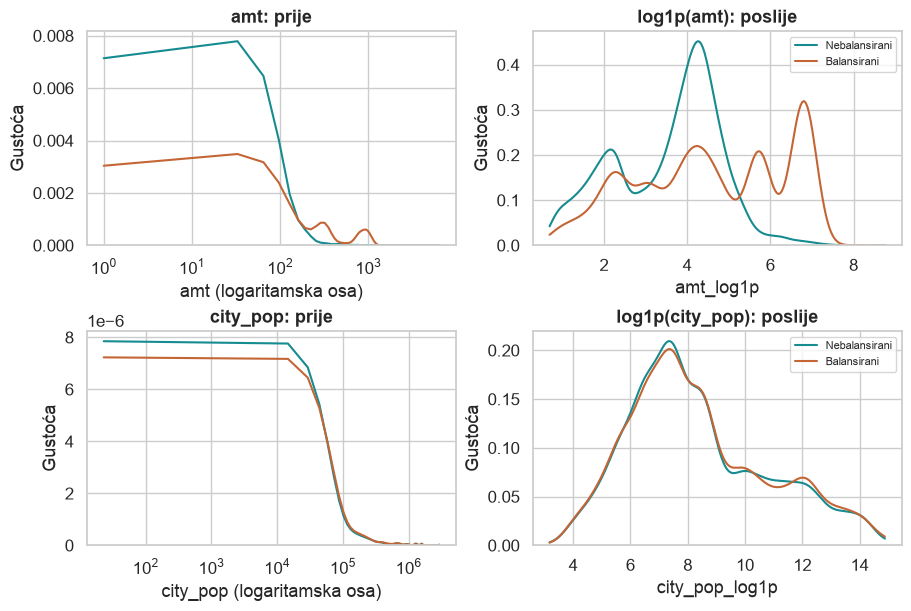

,mean,std,min,max,skew,outlier_count
atribut,,,,,,
lat,38.594,5.037,20.027,65.690,-0.200,48
long,-90.415,13.792,-165.672,-67.950,-1.096,521
age_years,46.093,17.261,13.993,95.484,0.601,33
distance_km,76.137,29.156,1.610,143.726,-0.248,0
hour_sin,-0.134,0.693,-1.000,1.000,0.316,0
hour_cos,-0.028,0.708,-1.000,1.000,0.043,0
day_of_week_sin,-0.107,0.686,-0.975,0.975,0.224,0
day_of_week_cos,0.132,0.708,-0.901,1.000,-0.280,0
amt_log1p,3.540,1.280,0.693,8.754,-0.312,6


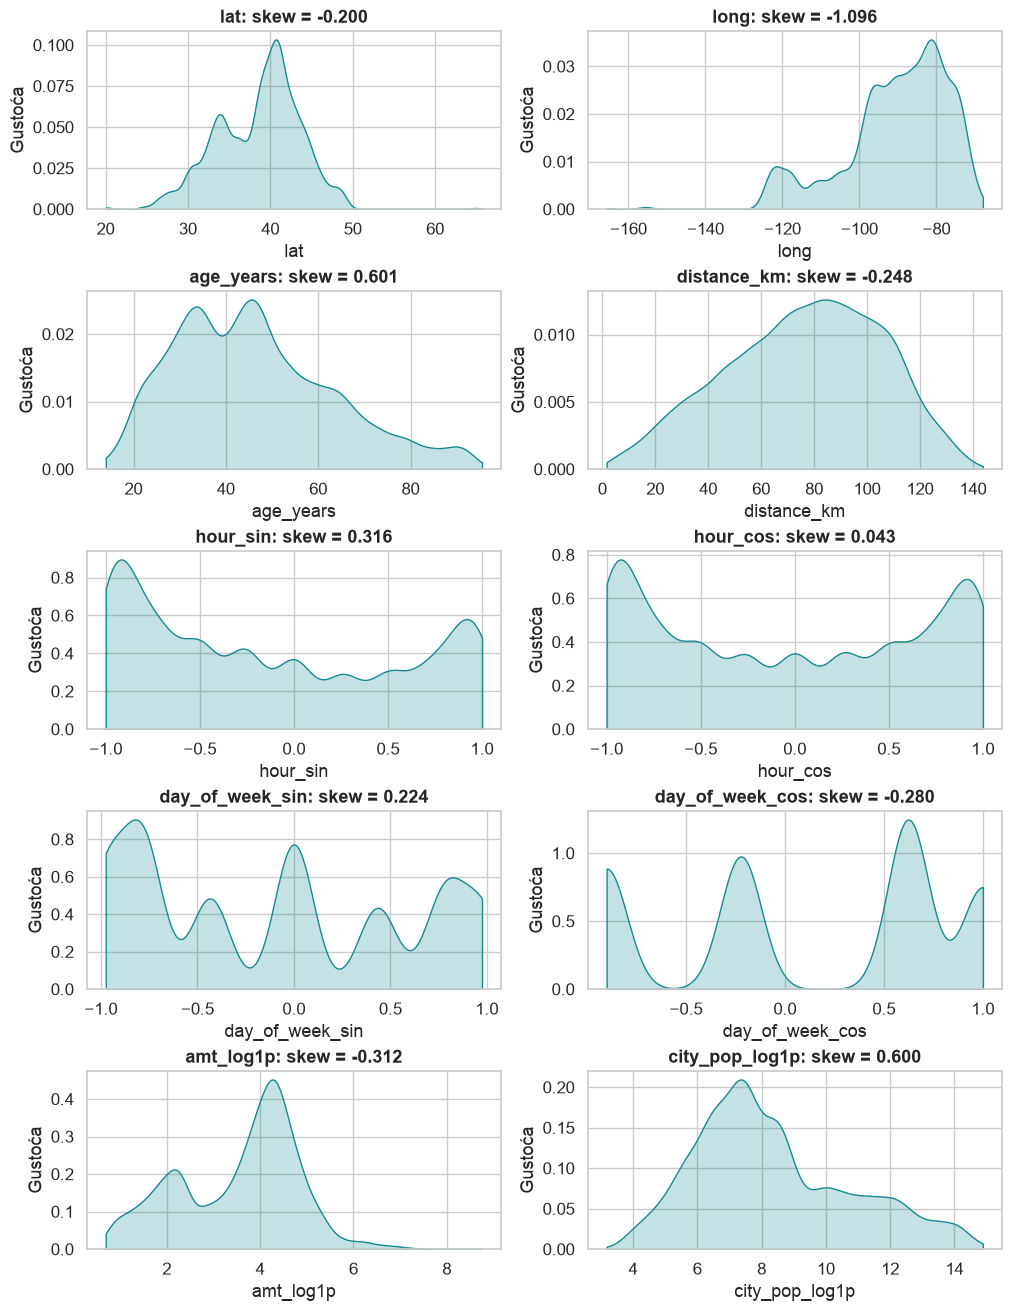

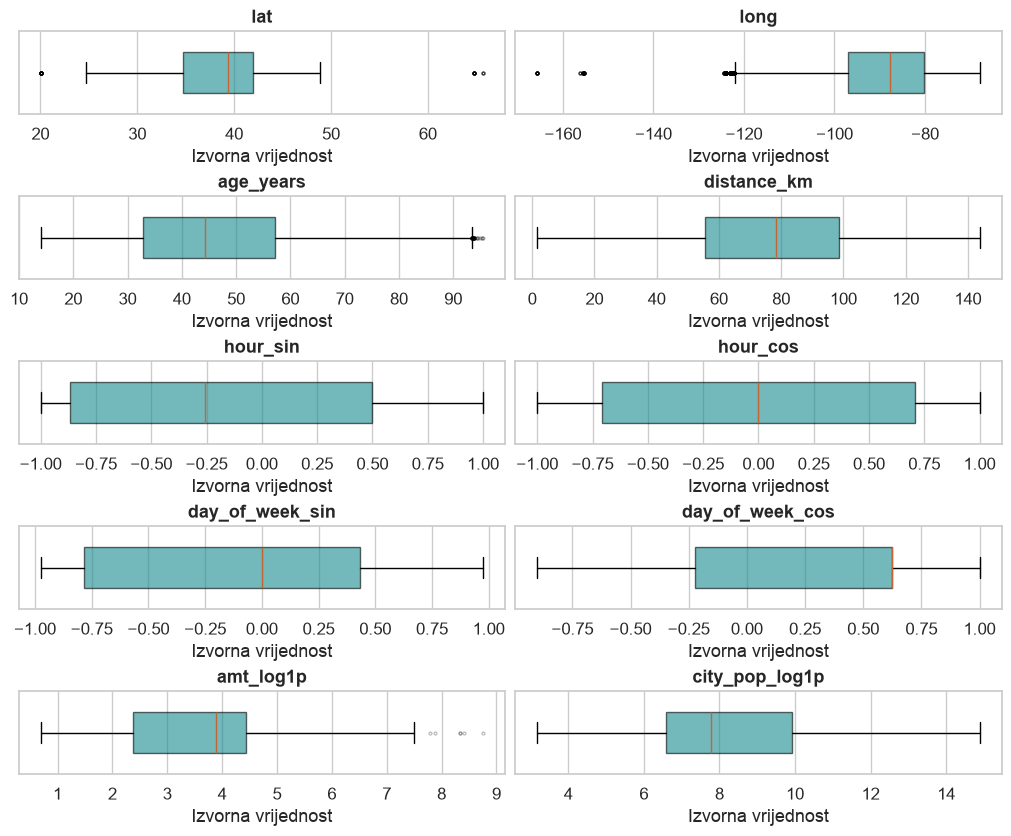

,mean,std,min,max,skew,outlier_count
atribut,,,,,,
lat,38.620,5.129,20.027,66.693,0.026,66
long,-90.275,14.085,-165.672,-67.950,-1.196,491
age_years,47.566,18.059,13.993,95.484,0.481,0
distance_km,76.378,28.847,0.739,144.523,-0.241,0
hour_sin,-0.110,0.598,-1.000,1.000,0.337,0
hour_cos,0.337,0.719,-1.000,1.000,-0.752,0
day_of_week_sin,-0.096,0.692,-0.975,0.975,0.196,0
day_of_week_cos,0.073,0.712,-0.901,1.000,-0.146,0
amt_log1p,4.550,1.778,0.693,8.754,-0.210,0


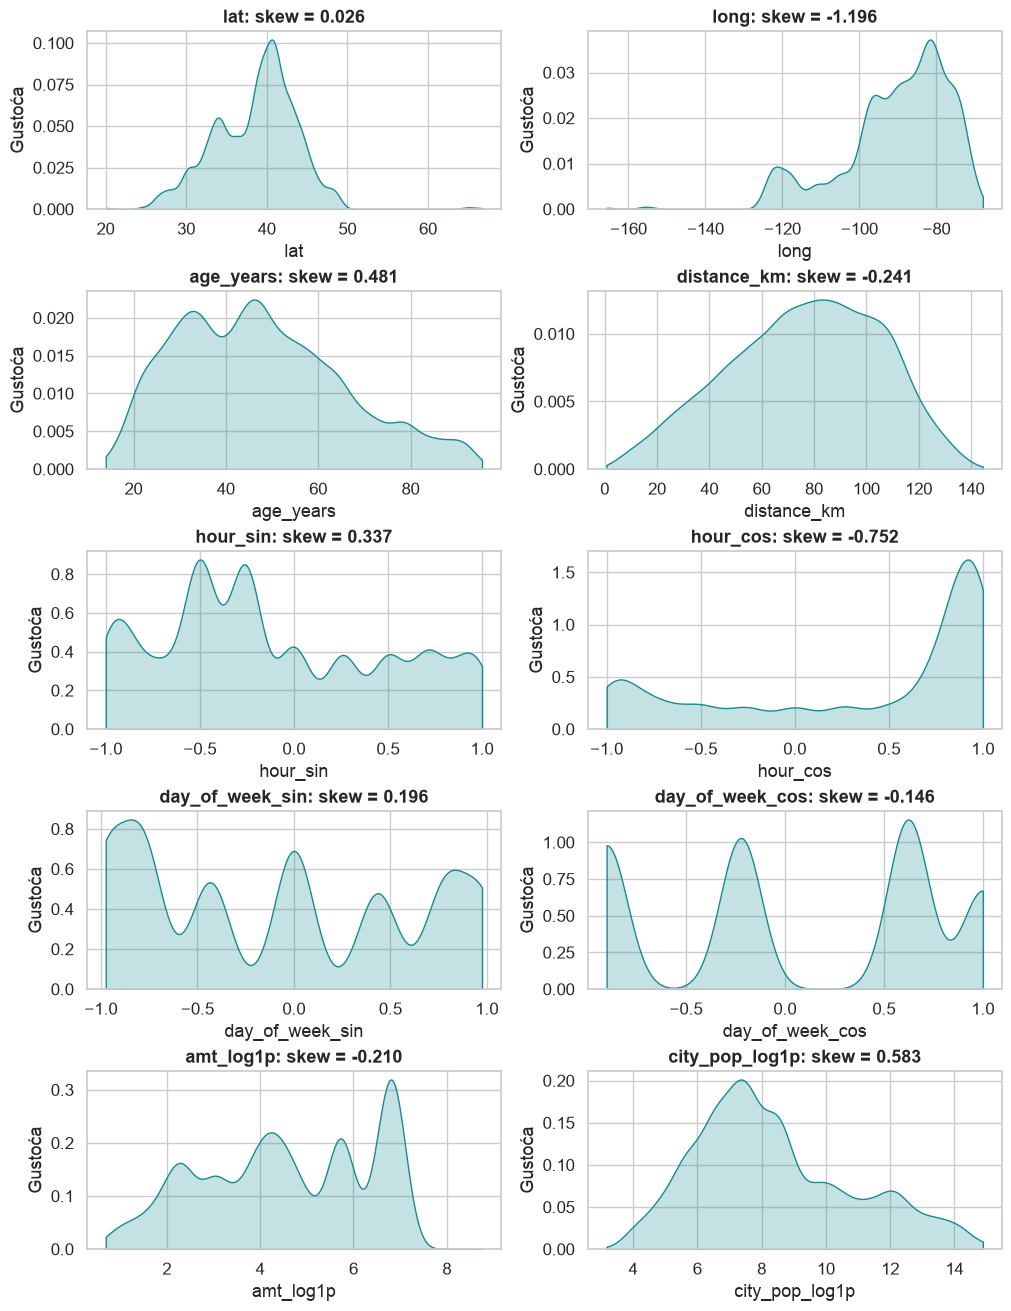

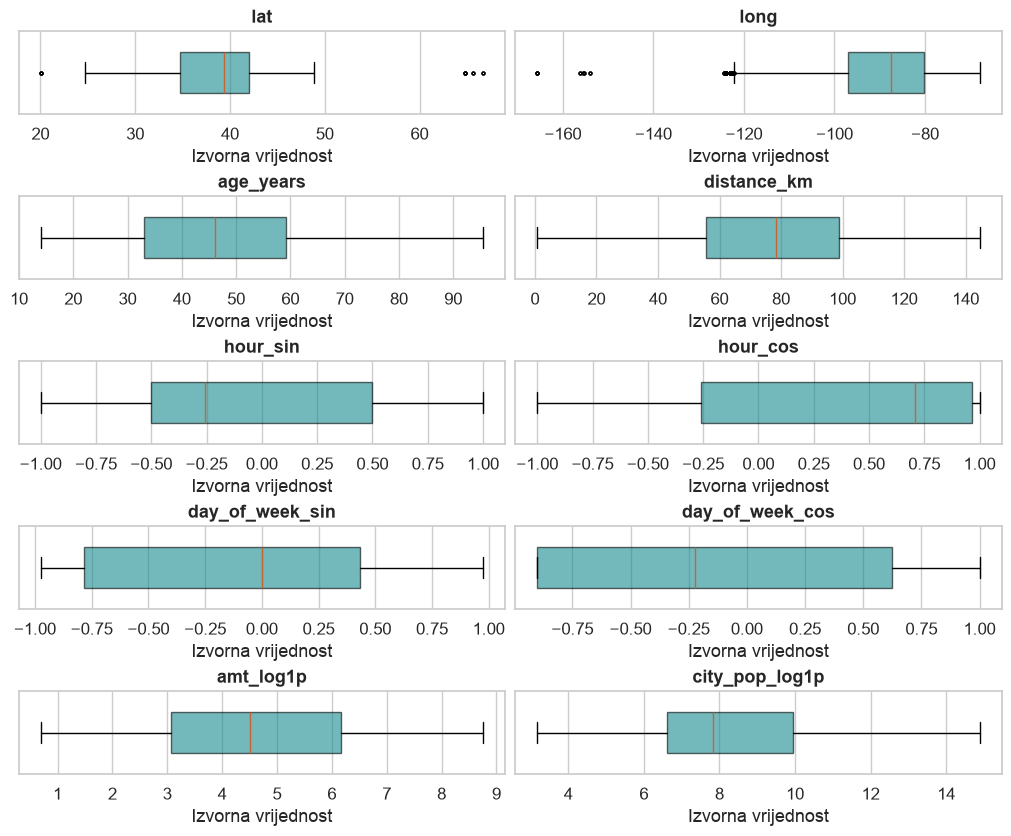

In [24]:
transform_rows = []
for name in ['unbalanced','balanced']:
    for c in ['amt','city_pop']:
        before = numeric_profile(datasets[name],[c]).iloc[0]
        after = numeric_profile(feature_data[name],[f'{c}_log1p']).iloc[0]
        transform_rows.append({'Skup':name,'Atribut':c,'Skew prije':before['skew'],'Skew poslije':after['skew'],
                               'IQR prije':int(before.outlier_count),'IQR poslije':int(after.outlier_count)})
transform_summary = pd.DataFrame(transform_rows)
display(transform_summary)
fig,axes = plt.subplots(2,2,figsize=(9,6),constrained_layout=True)
for row,c in enumerate(['amt','city_pop']):
    for name,color in [('unbalanced',COLORS[0]),('balanced',COLORS[1])]:
        sns.kdeplot(x=datasets[name][c],ax=axes[row,0],cut=0,label=dataset_labels[name],color=color)
        sns.kdeplot(x=feature_data[name][c+'_log1p'],ax=axes[row,1],cut=0,label=dataset_labels[name],color=color)
    axes[row,0].set(title=f'{c}: prije',ylabel='Gustoća')
    axes[row,0].set_xscale('log')
    axes[row,0].set_xlabel(c+' (logaritamska osa)')
    axes[row,1].set(title=f'log1p({c}): poslije',ylabel='Gustoća')
    axes[row,1].legend(fontsize=8)
show_plot(fig,'transformacije_gustoce.png')
for name in ['unbalanced','balanced']:
    table = numeric_profile(feature_data[name],numeric_features)
    display(table[['mean','std','min','max','skew','outlier_count']])
    numeric_plots(feature_data[name],numeric_features,f'gustoce_poslije_{name}.png',f'boxplotovi_poslije_{name}.png')

### 1.4-C Kodiranje i standardizacija

Izostavljamo `city` i `zip`, a zadržavamo `merchant`, `category`, `gender`, `state` i `job`. Nominalne vrijednosti nemaju prirodan poredak, pa koristimo one-hot. Za `merchant` i `job` kategorije s manje od **20 transakcija** grupišemo u zajedničku rijetku kategoriju (`min_frequency=20`). Ostale tri kolone kodiramo bez tog grupisanja.

Prag je izabran iz pregleda frekvencija, bez korištenja cilja: čuva zasebne kategorije za više od 90% transakcija po oba atributa. To je obrazložena pripremna odluka zasnovana na frekvencijama kategorija. Za prikaz pripreme zajednički pretprocesor prilagođavamo uniji jedinstvenih transakcija. Pri kasnijoj procjeni prvo se dijele podaci, a frekvencije, kategorije, medijani i skale određuju samo iz treninga.

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy import sparse

def make_preprocessor():
    return ColumnTransformer([
        ('numeric', Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]), numeric_features),
        ('nominal', Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                             ('onehot',OneHotEncoder(handle_unknown='ignore',dtype=np.float64))]), ['category','gender','state']),
        ('grouped', Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                             ('onehot',OneHotEncoder(min_frequency=20,handle_unknown='infrequent_if_exist',dtype=np.float64))]), ['merchant','job'])
    ], sparse_threshold=1.0)

reference = pd.concat(list(datasets.values()),ignore_index=True).drop_duplicates('trans_num')
preprocessor = make_preprocessor()
preprocessor.fit(prepare_features(reference))
encoded = {name:sparse.csr_matrix(preprocessor.transform(data)) for name,data in feature_data.items()}
feature_names = preprocessor.get_feature_names_out()
prepared_summary = pd.DataFrame([
    {'Skup':dataset_labels[name], 'Redovi':len(data), 'Legitimne':int(data.is_fraud.eq(0).sum()),
     'Prevare':int(data.is_fraud.eq(1).sum()), 'Udio prevara (%)':100*data.is_fraud.mean(),
     'Kodirane kolone':encoded[name].shape[1]}
    for name,data in datasets.items()])
display(prepared_summary)


,Skup,Redovi,Legitimne,Prevare,Udio prevara (%),Kodirane kolone
0,Balansirani,15012,7506,7506,50.000,1026
1,Nebalansirani,15000,14913,87,0.580,1026


### 1.4-D Čuvanje pripremljenih skupova

Datoteke `fraud_balanced_prepared.npz` i `fraud_15k_prepared.npz` sadrže po jedan cijeli pripremljeni skup: kodiranu matricu, cilj, oznake transakcija, nazive kolona i 15 ulaza prije standardizacije i one-hot kodiranja. Čuvanje tih ulaza omogućava da se grupisanje, kodiranje i skaliranje prilagode isključivo trening dijelu kada se podaci razdvoje. Ulazni CSV-ovi ostaju nepromijenjeni.

In [26]:
encoding_rows=[]
for c in ['category','gender','state','merchant','job']:
    branch='grouped' if c in ['merchant','job'] else 'nominal'
    columns=['merchant','job'] if branch=='grouped' else ['category','gender','state']
    encoder=preprocessor.named_transformers_[branch].named_steps['onehot']
    i=columns.index(c)
    infrequent=encoder.infrequent_categories_[i] if branch=='grouped' else None
    grouped_count=0 if infrequent is None else len(infrequent)
    resulting=len(encoder.categories_[i])-grouped_count+(grouped_count>0)
    encoding_rows.append({'Atribut':c,'Izvornih kategorija':len(encoder.categories_[i]),
                          'Grupisano':grouped_count,'Izlaznih kolona':int(resulting)})
encoding_summary=pd.DataFrame(encoding_rows)
display(encoding_summary)


,Atribut,Izvornih kategorija,Grupisano,Izlaznih kolona
0,category,14,0,14
1,gender,2,0,2
2,state,51,0,51
3,merchant,693,142,552
4,job,494,98,397


In [27]:
filenames = {'balanced':'fraud_balanced_prepared.npz', 'unbalanced':'fraud_15k_prepared.npz'}
for name, data in datasets.items():
    matrix = encoded[name]
    np.savez_compressed(
        OUTPUT / filenames[name], format=np.asarray(b'csr'), shape=np.asarray(matrix.shape),
        data=matrix.data, indices=matrix.indices, indptr=matrix.indptr,
        y=data.is_fraud.to_numpy(dtype=np.int8), trans_num=data.trans_num.to_numpy(dtype=str),
        feature_names=np.asarray(feature_names, dtype=str),
        numeric_columns=np.asarray(numeric_features, dtype=str),
        categorical_columns=np.asarray(categorical_features, dtype=str),
        numeric_values=feature_data[name][numeric_features].to_numpy(dtype=float),
        categorical_values=feature_data[name][categorical_features].to_numpy(dtype=str))
print('Sačuvana su oba kompletna pripremljena skupa.')

Sačuvana su oba kompletna pripremljena skupa.


## 2.1 Odabir algoritama i raspodjela rada

Biramo pet pojedinačnih klasifikacijskih algoritama, po jedan za svakog člana. Izbor obuhvata grananje po pravilima, linearnu granicu, granicu s radijalnom jezgrom, lokalno susjedstvo i neuronsku mrežu.

| Član tima | Algoritam | Razlog izbora |
|---|---|---|
| Aldin Velić | Stablo odlučivanja (`DecisionTreeClassifier`) | Čitljiva pravila grananja i nelinearni odnosi. |
| Bakir Činjarević | Logistička regresija (`LogisticRegression`) | Binarni ishod i tumačenje doprinosa standardizovanih numeričkih i one-hot ulaza. |
| Danijal Alibegović | SVM s radijalnom jezgrom (`SVC`) | Nelinearna granica na standardizovanim ulazima. |
| Haris Macić | k-najbližih susjeda (`KNeighborsClassifier`) | Lokalna sličnost transakcija; važnost skale i dimenzionalnosti. |
| Kerim Hajdar | Višeslojni perceptron (`MLPClassifier`) | Nelinearne interakcije numeričkih i kategoričkih karakteristika. |

Ovaj odjeljak utvrđuje izbor, zaduženja i razloge prikladnosti. Svaki algoritam koristi isti definisani cilj i iste pripremljene vrste ulaza.